# Residential Rent Prediction — Machine Learning Case Study

**Case Study 36 · Semester V Machine Learning**

Predicting the monthly rent of a residential unit from its attributes — size,
bedrooms, floor, furnishing, locality and tenant preference — across six Indian
cities, and deploying the result as an interactive estimation tool.

---

### What this notebook covers

| Section | Contents |
|---|---|
| 1–2 | Data profiling on the real CSV, before any preprocessing is written |
| 3 | Exploratory data analysis |
| 4 | Preprocessing: floor parsing, imputation, area-type normalisation, encoding |
| 5 | Outlier detection and treatment |
| 6 | Model comparison — six variants, 5-fold CV and a held-out test set |
| 7 | Residual plots for **all** models |
| 8 | The outlier experiment — the core comparative study |
| 9 | Deep residual analysis of the selected model |
| 10 | Feature importance and the locality ablation |
| 11 | Model selection justification |
| 12 | Per-city performance breakdown |
| 13 | Prediction intervals |
| 14 | **Final Analysis** — the seven questions, answered explicitly |
| 15 | Limitations and real-world applicability |

### Method note

Every transformation lives in `src/` and is imported here, by `train.py`, and by
the Streamlit app. Nothing is reimplemented in this notebook, so the analysis
below describes exactly the code that produced the saved model.

## 0. Setup

`RETRAIN` controls how the heavy model-fitting sections behave.

* `RETRAIN = False` (default) — the model tables are read from
  `models/metrics.json`, written by the last `python train.py` run. The notebook
  then executes in seconds and every number matches the saved model exactly.
* `RETRAIN = True` — the notebook refits everything inline. Same code, same
  seed, same numbers; it simply takes several minutes.

The exploratory and preprocessing sections always compute live — they are fast.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

# Make the project's `src/` package importable from inside notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config as cfg
from src import plots as P
from src.data import load_data, load_glossary, profile_data
from src.evaluate import format_inr
from src.preprocess import (add_eda_features, detect_outliers,
                            empirical_area_ratios, parse_floor, treat_outliers,
                            FeatureEngineer, build_preprocessor)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

RETRAIN = False   # see the note above

METRICS_PATH = cfg.METRICS_PATH
if not METRICS_PATH.exists():
    raise FileNotFoundError(
        f"{METRICS_PATH} not found. Run `python train.py` from the project "
        "root first -- it writes every table this notebook reports."
    )
with open(METRICS_PATH) as f:
    M = json.load(f)

def table(records, cols=None):
    d = pd.DataFrame(records)
    return d[[c for c in cols if c in d.columns]] if cols else d

def fig(key):
    rel = M.get("figures", {}).get(key)
    return Image(str(ROOT / rel)) if rel and (ROOT / rel).exists() else None

print(f"scikit-learn random_state = {cfg.RANDOM_STATE}")
print(f"metrics.json from a run taking {float(M.get('elapsed_minutes', 0)):.1f} min")

scikit-learn random_state = 42
metrics.json from a run taking 8.4 min


## 1. Profiling the real data — before writing any preprocessing

The specification's first instruction is to profile the actual CSV rather than
assume its shape. Column names are matched *exactly* by the `ColumnTransformer`,
so spelling and capitalisation matter, and several of the assumptions that look
obvious from a data dictionary turn out to be wrong here.

In [2]:
df = load_data(validate=True)   # raises if the header does not match cfg.EXPECTED_RAW_COLUMNS
profile = profile_data(df)

print(f"Rows: {profile['n_rows']:,}   Columns: {profile['n_cols']}")
print(f"Duplicate rows: {profile['duplicate_rows']}")
print(f"Total explicit NaNs in the entire frame: {profile['total_nulls']}")
df.head()

Rows: 4,746   Columns: 12
Duplicate rows: 0
Total explicit NaNs in the entire frame: 0


,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [3]:
pd.DataFrame({
    "dtype": profile["dtypes"],
    "nulls": profile["null_counts"],
    "unique": {c: int(df[c].nunique()) for c in df.columns},
}).rename_axis("column")

,dtype,nulls,unique
column,,,
Posted On,str,0,81
BHK,int64,0,6
Rent,int64,0,243
Size,int64,0,615
Floor,str,0,480
Area Type,str,0,3
Area Locality,str,0,2235
City,str,0,6
Furnishing Status,str,0,3


### The dataset glossary

In [4]:
print(load_glossary())

BHK: Number of Bedrooms, Hall, Kitchen.

Rent: Rent of the Houses/Apartments/Flats.

Size: Size of the Houses/Apartments/Flats in Square Feet.

Floor: Houses/Apartments/Flats situated in which Floor and Total Number of Floors (Example: Ground out of 2, 3 out of 5, etc.)

Area Type: Size of the Houses/Apartments/Flats calculated on either Super Area or Carpet Area or Build Area.

Area Locality: Locality of the Houses/Apartments/Flats.

City: City where the Houses/Apartments/Flats are Located.

Furnishing Status: Furnishing Status of the Houses/Apartments/Flats, either it is Furnished or Semi-Furnished or Unfurnished.

Tenant Preferred: Type of Tenant Preferred by the Owner or Agent.

Bathroom: Number of Bathrooms.

Point of Contact: Whom should you contact for more information regarding the Houses/Apartments/Flats.


### 1.1 Target distribution — why the target must be log-transformed

In [5]:
r = profile["rent"]
display(Markdown(f'''
| statistic | value |
|---|---|
| minimum | {format_inr(r["min"])} |
| 1st percentile | {format_inr(r["p01"])} |
| 25th percentile | {format_inr(r["p25"])} |
| **median** | **{format_inr(r["median"])}** |
| mean | {format_inr(r["mean"])} |
| 75th percentile | {format_inr(r["p75"])} |
| 99th percentile | {format_inr(r["p99"])} |
| **maximum** | **{format_inr(r["max"])}** |
| skewness (raw) | **{r["skew"]:.2f}** |
| skewness of `log1p(Rent)` | **{r["skew_log1p"]:.2f}** |

The maximum rent is **{r["max"] / r["median"]:.0f}x the median**, and the mean sits
far above the median. A skew of {r["skew"]:.1f} is extreme; squared-error
regression on this target would be dominated by a handful of listings.

Taking `log1p` collapses the skew to {r["skew_log1p"]:.2f} — close to symmetric.
Every model is therefore trained on `log1p(Rent)`, and **every reported metric is
inverted with `expm1` first**, so all errors below are in rupees and mean what
they appear to mean.
'''))


| statistic | value |
|---|---|
| minimum | ₹1,200 |
| 1st percentile | ₹4,000 |
| 25th percentile | ₹10,000 |
| **median** | **₹16,000** |
| mean | ₹34,993 |
| 75th percentile | ₹33,000 |
| 99th percentile | ₹3,00,000 |
| **maximum** | **₹35,00,000** |
| skewness (raw) | **21.41** |
| skewness of `log1p(Rent)` | **0.91** |

The maximum rent is **219x the median**, and the mean sits
far above the median. A skew of 21.4 is extreme; squared-error
regression on this target would be dominated by a handful of listings.

Taking `log1p` collapses the skew to 0.91 — close to symmetric.
Every model is therefore trained on `log1p(Rent)`, and **every reported metric is
inverted with `expm1` first**, so all errors below are in rupees and mean what
they appear to mean.


### 1.2 The `Floor` column — missing values hidden inside a string

`Floor` stores two facts in one text field. The missing values this dataset
contains are *not* stored as NaN — they are rows where the "out of N" half of the
string is simply absent.

In [6]:
f = profile["floor"]
print(f"{f['n_distinct_raw']} distinct raw strings, but only {len(f['patterns'])} "
      f"structural patterns:\n")
for pat, n in f["patterns"].items():
    print(f"  {pat:<28} {n:>5}")
print(f"\nRows with no 'out of' part (total_floors genuinely missing): "
      f"{f['missing_total_floors']}")
print(f"Examples: {f['examples_without_out_of']}")

480 distinct raw strings, but only 6 structural patterns:

  N out of N                    3782
  Ground out of N                926
  Upper Basement out of N         23
  Lower Basement out of N         11
  N                                3
  Ground                           1

Rows with no 'out of' part (total_floors genuinely missing): 4
Examples: ['3', 'Ground', '1']


### 1.3 `Area Locality` — why one-hot encoding is not an option

In [7]:
loc = profile["locality"]
display(Markdown(f'''
* **{loc["n_unique"]:,}** distinct localities across {profile["n_rows"]:,} listings
* **{loc["appearing_once"]:,}** appear exactly once — that is
  **{loc["share_of_rows_in_singleton_localities"]:.1%}** of all rows
* {loc["appearing_twice_or_fewer"]:,} appear twice or fewer

One-hot encoding would add {loc["n_unique"]:,} near-empty columns to a dataset of
{profile["n_rows"]:,} rows. The model would memorise individual listings rather
than learn a locality effect. `TargetEncoder` with empirical-Bayes smoothing is
used instead: each locality is represented by the average (log) rent of listings
in it, shrunk towards the global average in proportion to how little evidence
supports it.
'''))
pd.Series(loc["top_10"]).rename("listings").to_frame().head(10)


* **2,235** distinct localities across 4,746 listings
* **1,465** appear exactly once — that is
  **30.9%** of all rows
* 1,794 appear twice or fewer

One-hot encoding would add 2,235 near-empty columns to a dataset of
4,746 rows. The model would memorise individual listings rather
than learn a locality effect. `TargetEncoder` with empirical-Bayes smoothing is
used instead: each locality is represented by the average (log) rent of listings
in it, shrunk towards the global average in proportion to how little evidence
supports it.


,listings
Bandra West,37
Gachibowli,29
Electronic City,24
Velachery,22
"Miyapur, NH 9",22
Madipakkam,20
Chembur,19
K R Puram,19
Laxmi Nagar,19
Kondapur,18


### 1.4 `Posted On` — profiled, then dropped, with the reason stated

The specification requires that this column be dropped only after confirming its
span is too short to be useful, and that the reasoning be recorded rather than
the column silently removed.

In [8]:
po = profile["posted_on"]
display(Markdown(f'''
Listings run from **{po["min"]}** to **{po["max"]}** — a span of
**{po["span_days"]} days** across {po["n_unique_dates"]} distinct dates.

**Decision: drop `Posted On`.** Roughly three months cannot express rent
inflation, seasonality or market drift. A month or day-of-week feature derived
from this window would fit noise specific to mid-2022 rather than any real
temporal signal, and would not transfer to a listing posted today. It is dropped
in `config.DROP_COLUMNS` with this reasoning attached.

This *is* itself a limitation of the dataset, and it is recorded as one in
section 15.
'''))


Listings run from **2022-04-13** to **2022-07-11** — a span of
**89 days** across 81 distinct dates.

**Decision: drop `Posted On`.** Roughly three months cannot express rent
inflation, seasonality or market drift. A month or day-of-week feature derived
from this window would fit noise specific to mid-2022 rather than any real
temporal signal, and would not transfer to a listing posted today. It is dropped
in `config.DROP_COLUMNS` with this reasoning attached.

This *is* itself a limitation of the dataset, and it is recorded as one in
section 15.


### 1.5 Discrepancies between the specification and the actual data

Profiling turned up four differences worth recording, because each one changes
the implementation.

In [9]:
display(Markdown(f'''
| # | Expected | Actually in the data | Consequence |
|---|---|---|---|
| 1 | `Bachelors_Family` | `Bachelors/Family` | Category strings are read from the CSV, never hard-coded |
| 2 | Owner / Agent / Builder | `Contact Owner` / `Contact Agent` / `Contact Builder` | Same |
| 3 | Three area types | **`Built Area` has {M["area_ratio_check"]["n_built_area_rows"]} rows** in the entire dataset | Its conversion ratio cannot be estimated empirically (section 4.3) |
| 4 | — | **`Contact Builder` has 1 row** | Such a level lands in either train or test but never both, so `OneHotEncoder(handle_unknown="ignore")` is mandatory, not optional |

Rare levels are **kept**, not dropped — discarding them would misrepresent the
dataset — and are handled by the encoder configuration instead.
'''))
pd.DataFrame([
    {"column": c, "level": lvl, "rows": n}
    for c, levels in profile["rare_levels"].items() for lvl, n in levels.items()
])


| # | Expected | Actually in the data | Consequence |
|---|---|---|---|
| 1 | `Bachelors_Family` | `Bachelors/Family` | Category strings are read from the CSV, never hard-coded |
| 2 | Owner / Agent / Builder | `Contact Owner` / `Contact Agent` / `Contact Builder` | Same |
| 3 | Three area types | **`Built Area` has 2 rows** in the entire dataset | Its conversion ratio cannot be estimated empirically (section 4.3) |
| 4 | — | **`Contact Builder` has 1 row** | Such a level lands in either train or test but never both, so `OneHotEncoder(handle_unknown="ignore")` is mandatory, not optional |

Rare levels are **kept**, not dropped — discarding them would misrepresent the
dataset — and are handled by the encoder configuration instead.


,column,level,rows
0,Area Type,Built Area,2
1,Point of Contact,Contact Builder,1


## 2. Exploratory data analysis

Every figure below is generated by `src/plots.py` and saved to
`reports/figures/`, so the notebook, the README and the Streamlit app all show
the same images.

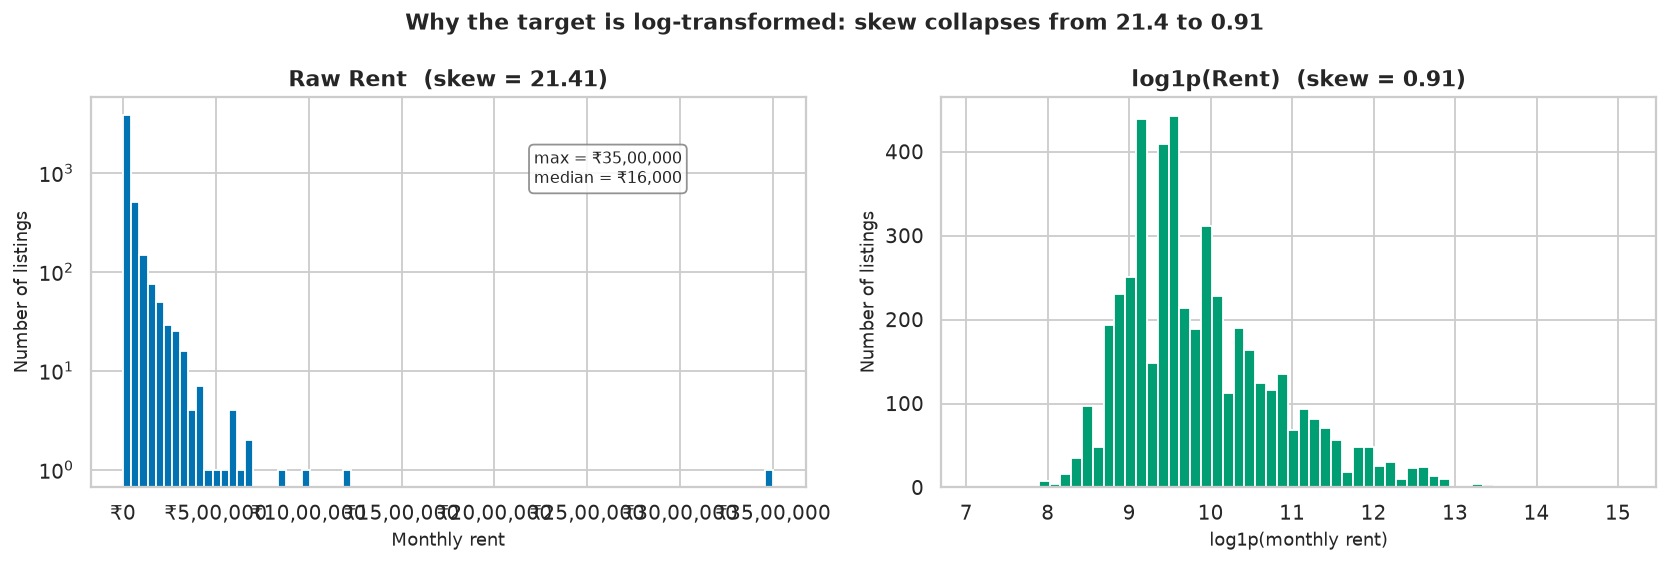

In [10]:
eda_df = add_eda_features(df)
paths = {}
paths["rent_distribution"] = P.plot_rent_distribution(df)
display(Image(str(ROOT / paths["rent_distribution"])))

The left panel is plotted on a log *count* axis — on a linear one the entire
distribution collapses into the first bar. The right panel is why the transform
is applied.

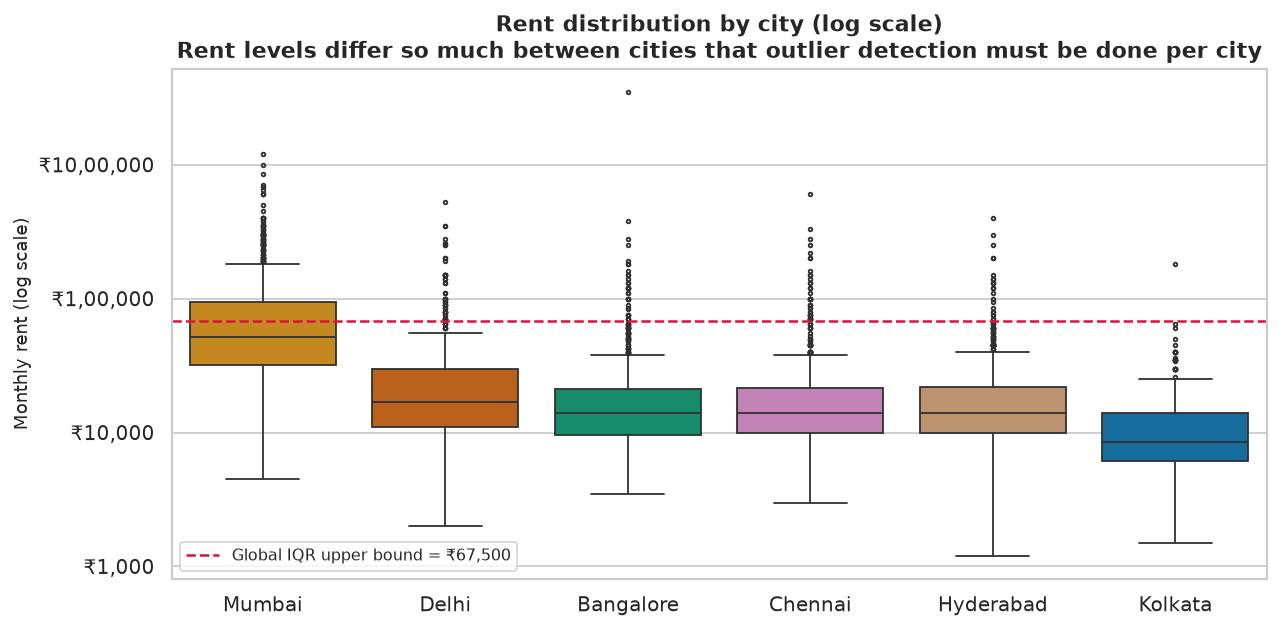

In [11]:
paths["rent_by_city"] = P.plot_rent_by_city(df)
display(Image(str(ROOT / paths["rent_by_city"])))

The dashed line is the upper bound a **global** IQR rule would impose. It sits
below Mumbai's box entirely — a global rule would classify a large share of
ordinary Mumbai flats as outliers. This is the evidence for detecting outliers
per city, quantified in section 5.

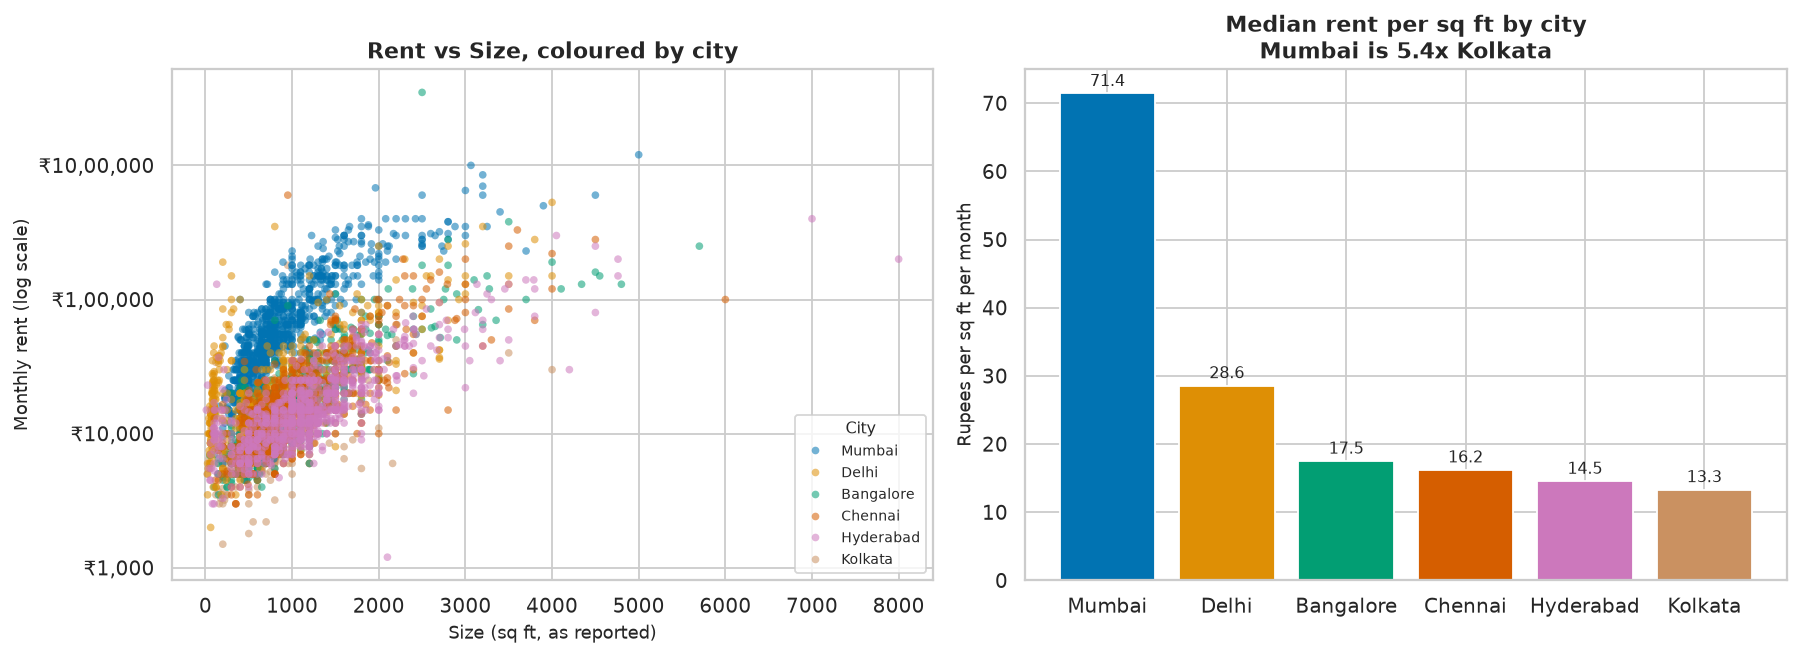

In [12]:
paths["rent_vs_size"] = P.plot_rent_vs_size(df)
display(Image(str(ROOT / paths["rent_vs_size"])))

In [13]:
rps = (df[cfg.TARGET] / df[cfg.COL_SIZE]).groupby(df[cfg.COL_CITY]).median().sort_values(ascending=False)
display(Markdown(f'''
### Key observation

**Rent scales with size, but the scaling factor is city-specific.**

{" · ".join(f"**{c}** {v:.1f}" for c, v in rps.items())} rupees per sq ft per month.

{rps.index[0]} is **{rps.iloc[0] / rps.iloc[-1]:.1f}x** {rps.index[-1]} per square
foot. A model that learned a single rent-per-square-foot coefficient would be
badly wrong in both cities at once, which is why `City` and `Area Locality` matter
as much as `Size` — quantified in the ablation in section 10.
'''))


### Key observation

**Rent scales with size, but the scaling factor is city-specific.**

**Mumbai** 71.4 · **Delhi** 28.6 · **Bangalore** 17.5 · **Chennai** 16.2 · **Hyderabad** 14.5 · **Kolkata** 13.3 rupees per sq ft per month.

Mumbai is **5.4x** Kolkata per square
foot. A model that learned a single rent-per-square-foot coefficient would be
badly wrong in both cities at once, which is why `City` and `Area Locality` matter
as much as `Size` — quantified in the ablation in section 10.


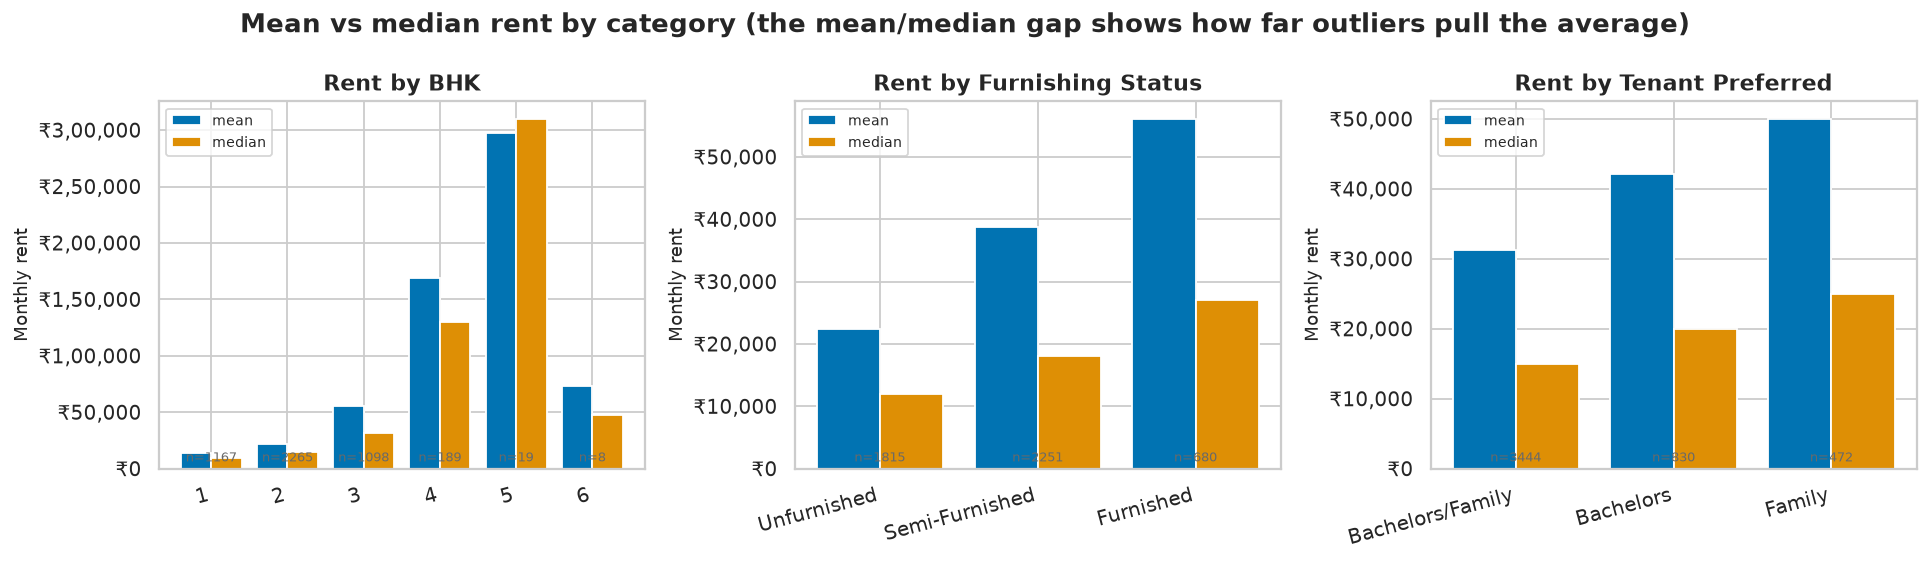

In [14]:
paths["avg_rent_by_category"] = P.plot_avg_rent_by_category(df)
display(Image(str(ROOT / paths["avg_rent_by_category"])))

The gap between the mean and median bars is itself informative: wherever the mean
sits far above the median, a few very expensive listings are pulling the average
up. That is the distortion the outlier experiment in section 8 measures.

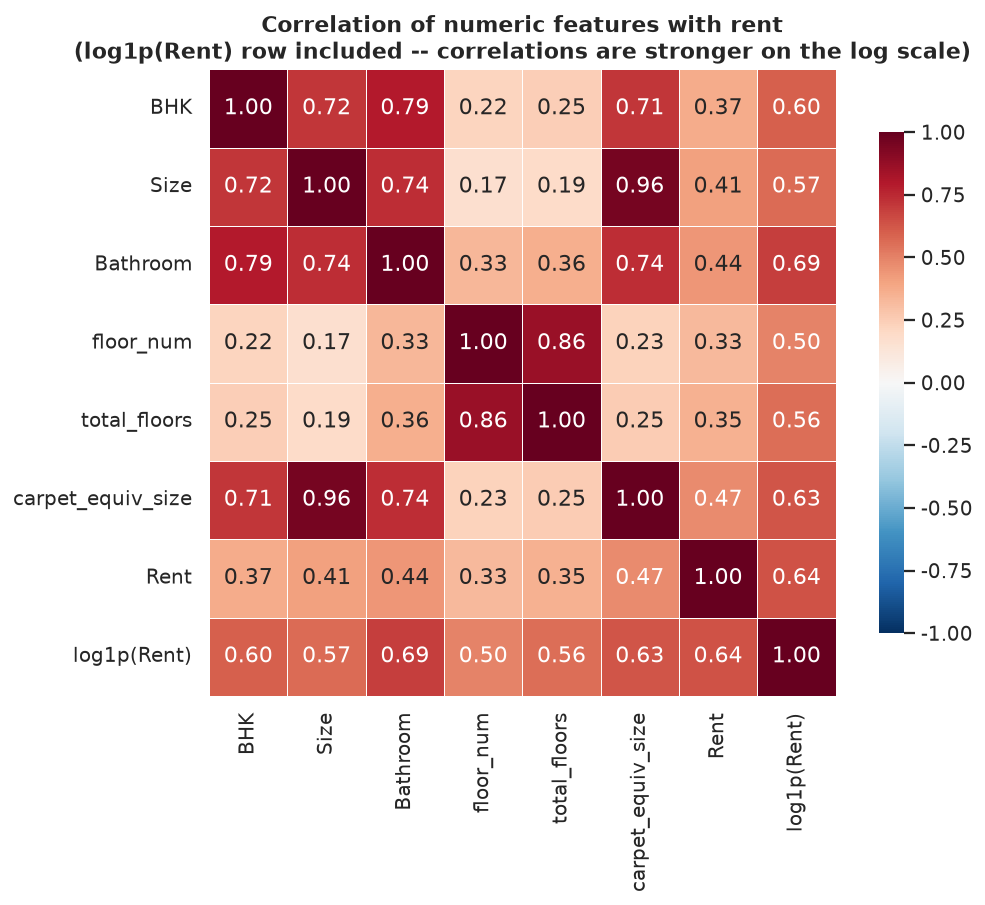

In [15]:
paths["correlation_heatmap"] = P.plot_correlation_heatmap(eda_df)
display(Image(str(ROOT / paths["correlation_heatmap"])))

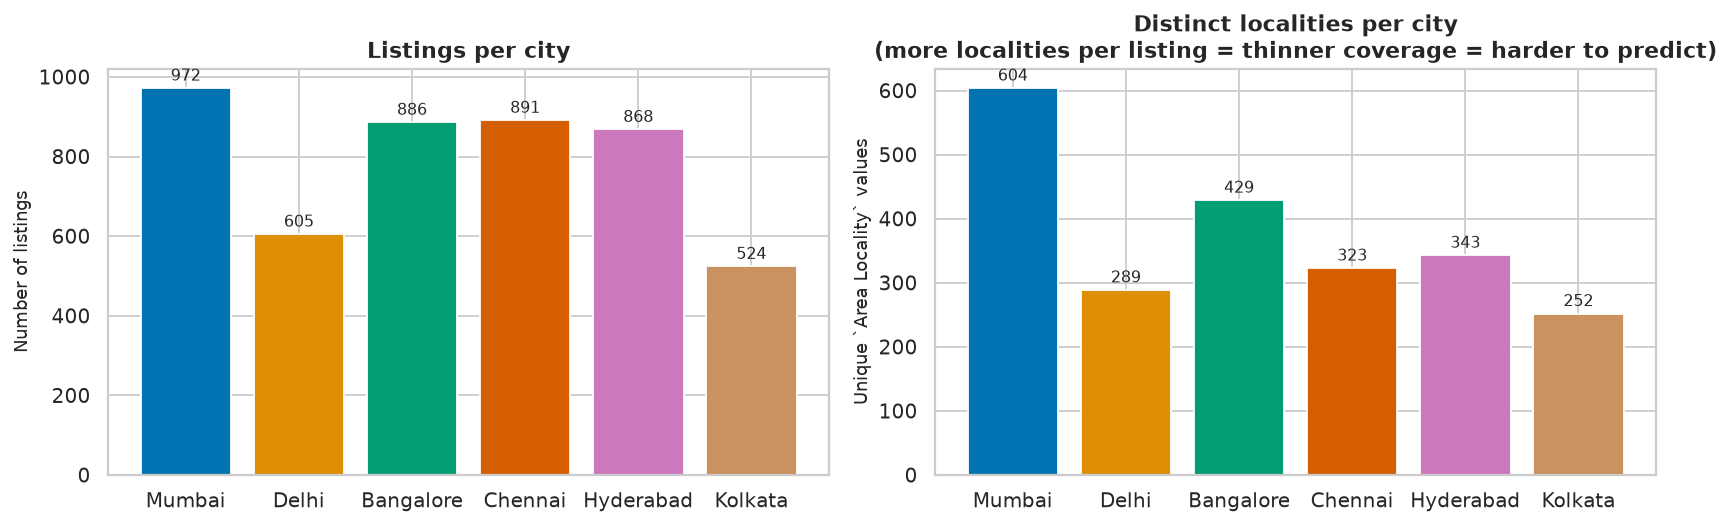

In [16]:
paths["listings_per_city"] = P.plot_listings_per_city(df)
display(Image(str(ROOT / paths["listings_per_city"])))

The right-hand panel matters for section 12: a city with many distinct localities
relative to its listing count has thinner evidence per locality, and is harder to
predict.

## 3. Preprocessing

All of this lives in `src/preprocess.py`. It is imported here, by `train.py` and
by the Streamlit app — never reimplemented.

### 3.1 Parsing `Floor` into two numeric features

Word-valued floors are mapped so that a linear model sees a sensible ordering:
`Ground` → 0, `Upper Basement` → −0.5, `Lower Basement` → −1.

In [17]:
demo = ["Ground out of 2", "3 out of 5", "Upper Basement out of 2",
        "Lower Basement out of 1", "3", "Ground"]
parsed = parse_floor(pd.Series(demo))
parsed.insert(0, "raw Floor", demo)
parsed

,raw Floor,floor_num,total_floors
0,Ground out of 2,0.0,2.0
1,3 out of 5,3.0,5.0
2,Upper Basement out of 2,-0.5,2.0
3,Lower Basement out of 1,-1.0,1.0
4,3,3.0,NaN
5,Ground,0.0,NaN


Rows with no "out of" part have a genuinely unknown building height. This is the
"handle missing floor values" objective: the missing values were hidden inside
the string rather than stored as NaN.

### 3.2 Imputation — learned on the training fold only

`FeatureEngineer` is a **stateful** transformer, not a `FunctionTransformer`. The
group medians it uses must be learned from training rows only; a stateless
function would recompute them from whatever frame it received, including
validation and test rows, leaking information inside cross-validation.

* `Size` below 50 sq ft is treated as missing, then imputed with the median
  `Size` of the same `(City, BHK)` group, falling back to the city median and
  then the global median.
* `total_floors` is imputed with the median for that city.

In [18]:
sizes = df[cfg.COL_SIZE]
print(f"Implausible sizes (< {cfg.MIN_VALID_SIZE:.0f} sq ft): "
      f"{(sizes < cfg.MIN_VALID_SIZE).sum()} rows, smallest = {sizes.min()} sq ft")

X_demo = df.drop(columns=[cfg.TARGET] + cfg.DROP_COLUMNS)
fe = FeatureEngineer().fit(X_demo)
X_eng = fe.transform(X_demo)

print(f"\nAfter imputation: minimum Size = {X_eng[cfg.COL_SIZE].min():.0f} sq ft, "
      f"NaNs in engineered features = "
      f"{int(X_eng[cfg.NUMERIC_FEATURES].isna().sum().sum())}")
X_eng[[cfg.COL_SIZE, cfg.FEAT_CARPET_EQUIV, cfg.FEAT_FLOOR_NUM,
       cfg.FEAT_TOTAL_FLOORS, cfg.FEAT_FLOOR_RATIO]].describe().round(2)

Implausible sizes (< 50 sq ft): 16 rows, smallest = 10 sq ft

After imputation: minimum Size = 50 sq ft, NaNs in engineered features = 0


,Size,carpet_equiv_size,floor_num,total_floors,floor_ratio
count,4746.00,4746.00,4746.00,4746.00,4746.00
mean,969.34,827.06,3.44,6.97,0.46
std,632.68,588.04,5.77,9.47,0.32
min,50.00,35.00,-1.00,1.00,-1.00
25%,555.75,450.00,1.00,2.00,0.22
50%,850.00,700.00,2.00,4.00,0.50
75%,1200.00,1015.00,3.00,6.00,0.67
max,8000.00,7000.00,76.00,89.00,1.00


### 3.3 Area-type normalisation — and testing the conventional ratios

`Size` is reported under three different conventions and is **not comparable
across them**. The conventional Indian real-estate ratios treat carpet area as
roughly 70% of super built-up area, with built-up area in between.

The specification asks for these ratios to be derived empirically as well, and to
report whether the observed ratios match. Within each `(City, BHK)` group — where
genuinely comparable flats sit side by side — the median reported `Size` of each
area type is compared against the median for carpet-area listings.

In [19]:
ratios = empirical_area_ratios(df)
summary = (ratios.groupby("area_type")
           .agg(n_groups=("observed_ratio_to_carpet", "size"),
                observed_median=("observed_ratio_to_carpet", "median"),
                observed_mean=("observed_ratio_to_carpet", "mean"),
                observed_min=("observed_ratio_to_carpet", "min"),
                observed_max=("observed_ratio_to_carpet", "max"),
                conventional=("conventional_ratio", "first")))
display(summary.round(3))

n_built = int((df[cfg.COL_AREA_TYPE] == "Built Area").sum())
obs = float(summary.loc["Super Area", "observed_median"])
display(Markdown(f'''
**Finding — the conventional ratios are *not* supported by this dataset.**

* For **Super Area**, the conventional multiplier to carpet-equivalent is
  **0.70**. The observed median across
  {int(summary.loc["Super Area", "n_groups"])} comparable `(City, BHK)` groups is
  **{obs:.2f}** — essentially 1.0. Within comparable flats, listings quoting super
  area report roughly the *same* number as listings quoting carpet area, which
  suggests `Area Type` is reported inconsistently rather than measured
  consistently.
* For **Built Area**, the ratio cannot be estimated at all: there are only
  **{n_built} such rows in the entire dataset**, so no `(City, BHK)` group reaches
  the minimum count. The conventional 0.85 is used as-is and flagged as an
  assumption.

**What is done about it.** `carpet_equiv_size` is still created as specified, but
the raw `Size` and `Area Type` columns are deliberately **kept as features
alongside it**. The models can therefore use whichever representation actually
carries signal rather than being forced through a conversion the data does not
support. Section 10's permutation importance shows which one they chose.
'''))

,n_groups,observed_median,observed_mean,observed_min,observed_max,conventional
area_type,,,,,,
Super Area,23,1.0,1.091,0.8,2.0,0.7



**Finding — the conventional ratios are *not* supported by this dataset.**

* For **Super Area**, the conventional multiplier to carpet-equivalent is
  **0.70**. The observed median across
  23 comparable `(City, BHK)` groups is
  **1.00** — essentially 1.0. Within comparable flats, listings quoting super
  area report roughly the *same* number as listings quoting carpet area, which
  suggests `Area Type` is reported inconsistently rather than measured
  consistently.
* For **Built Area**, the ratio cannot be estimated at all: there are only
  **2 such rows in the entire dataset**, so no `(City, BHK)` group reaches
  the minimum count. The conventional 0.85 is used as-is and flagged as an
  assumption.

**What is done about it.** `carpet_equiv_size` is still created as specified, but
the raw `Size` and `Area Type` columns are deliberately **kept as features
alongside it**. The models can therefore use whichever representation actually
carries signal rather than being forced through a conversion the data does not
support. Section 10's permutation importance shows which one they chose.


### 3.4 The `Size` × `Area Type` interaction

Tree models discover "a square foot means something different depending on the
measurement basis" by splitting on `Area Type` and then on `Size`. A linear model
cannot express that without an explicit product term, and is unfairly penalised
without one. The interaction columns are therefore added **for the Linear and
Polynomial models only**.

### 3.5 Leakage guard — `rent_per_sqft`

`rent_per_sqft` is `Rent / carpet_equiv_size`. It is a **function of the target**.
It is used for exploratory plots and for flagging implausible listings, and it is
**never** passed to a model: it is absent from `config.NUMERIC_FEATURES` and is
never selected by the `ColumnTransformer`. Including it would hand the model the
answer and produce a suspiciously perfect R².

### 3.6 Encoding, scaling, and the target-encoder leakage point

In [20]:
pre_tree = build_preprocessor("tree")
pre_linear = build_preprocessor("linear")
y_demo = np.log1p(df[cfg.TARGET])
print(f"tree family   -> {pre_tree.fit_transform(X_eng, y_demo).shape[1]} encoded columns")
print(f"linear family -> {pre_linear.fit_transform(X_eng, y_demo).shape[1]} encoded columns "
      f"(includes the Size x Area Type interaction, drops one level per one-hot "
      f"group to avoid collinearity)")

tree family   -> 26 encoded columns
linear family -> 24 encoded columns (includes the Size x Area Type interaction, drops one level per one-hot group to avoid collinearity)


| Column group | Treatment | Why |
|---|---|---|
| `BHK`, `Size`, `Bathroom`, `floor_num`, `total_floors`, `floor_ratio`, `carpet_equiv_size` | median imputation; `StandardScaler` for linear/polynomial only | trees are scale-invariant |
| `City`, `Furnishing Status`, `Tenant Preferred`, `Area Type`, `Point of Contact` | `OneHotEncoder(handle_unknown="ignore")` | few levels; `handle_unknown` is required because two levels have 1–2 rows |
| `Area Locality` | `TargetEncoder(smooth="auto")` | ~2,235 levels, most appearing once |

> **The marked leakage point.** `TargetEncoder` is placed **inside** the pipeline,
> so it is re-fitted on each training fold during cross-validation and never sees
> the validation fold's target. Fitting it once on the full training set before
> cross-validating would leak the answer into every CV score and produce
> optimistically biased results. scikit-learn's `TargetEncoder` additionally
> cross-fits internally during `fit_transform`, so even the training-fold
> encodings are out-of-fold.

## 4. Outlier detection and treatment

Two independent signals are used:

1. **Per-city IQR on `Rent`** — bounds computed *within* each city.
2. **Extreme `rent_per_sqft`** — catches listings whose rent is implausible
   *given their size*, which a rent-only rule misses.

Two treatment strategies are implemented and selectable: `remove` (drop the rows)
and `cap` (winsorize at the per-city 1st and 99th percentiles).

In [21]:
flags_pc = detect_outliers(df, per_city=True)
flags_gl = detect_outliers(df, per_city=False)
ov = pd.DataFrame(M["outlier_overview"]).set_index("City")
display(ov)

mum = ov.loc["Mumbai"]
q1, q3 = df[cfg.TARGET].quantile([.25, .75])
gub = q3 + 1.5 * (q3 - q1)
display(Markdown(f'''
**Why per-city, quantitatively.** The global IQR upper bound is
**{format_inr(gub)}**, while Mumbai's *median* rent is
**{format_inr(df[df[cfg.COL_CITY] == "Mumbai"][cfg.TARGET].median())}**.

A single global rule would therefore flag **{int(mum["global_flagged"])} of
{int(mum["n"])} Mumbai listings ({mum["global_pct"]}%)** as outliers — over a third
of the city — while flagging only {ov.loc["Hyderabad", "global_pct"]}% in
Hyderabad. The per-city rule flags a consistent
{ov["per_city_pct"].min()}–{ov["per_city_pct"].max()}% everywhere.

₹1.5 lakh is genuinely anomalous in Kolkata and entirely ordinary in South Mumbai.
'''))

,n,per_city_flagged,global_flagged,per_city_pct,global_pct
City,,,,,
Bangalore,886,91,36,10.3,4.1
Chennai,891,87,46,9.8,5.2
Delhi,605,64,68,10.6,11.2
Hyderabad,868,85,26,9.8,3.0
Kolkata,524,36,16,6.9,3.1
Mumbai,972,104,367,10.7,37.8



**Why per-city, quantitatively.** The global IQR upper bound is
**₹67,500**, while Mumbai's *median* rent is
**₹52,000**.

A single global rule would therefore flag **367 of
972 Mumbai listings (37.8%)** as outliers — over a third
of the city — while flagging only 3.0% in
Hyderabad. The per-city rule flags a consistent
6.9–10.7% everywhere.

₹1.5 lakh is genuinely anomalous in Kolkata and entirely ordinary in South Mumbai.


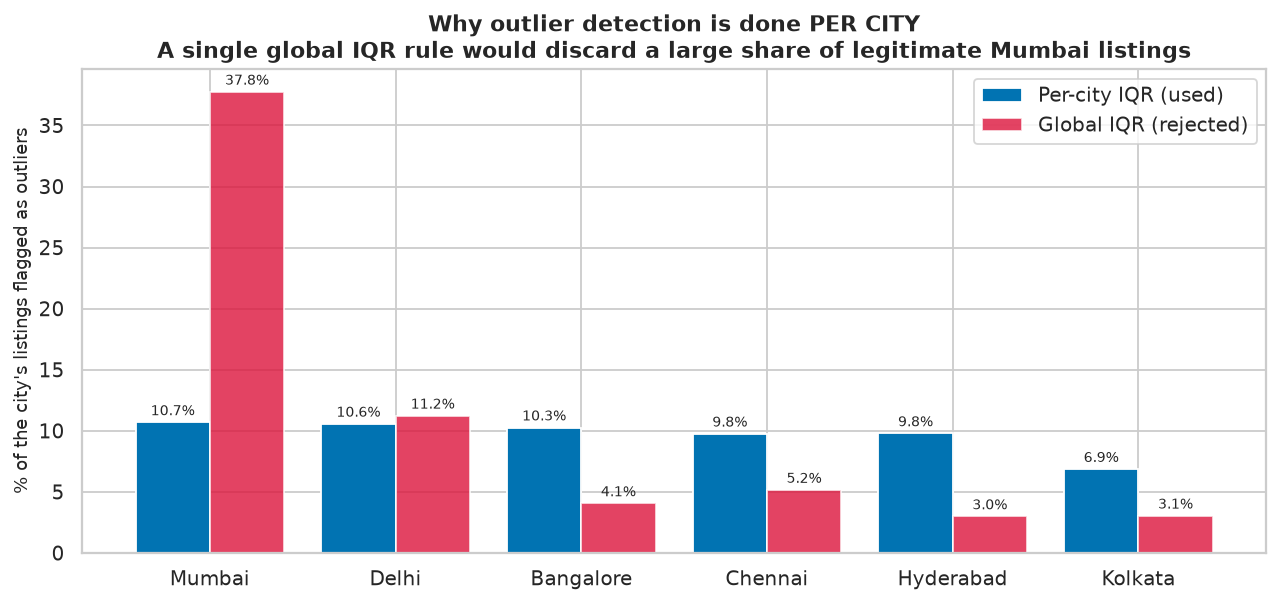

In [22]:
paths["outlier_per_city_vs_global"] = P.plot_outlier_overview(
    df, flags_pc["is_outlier"], flags_gl["is_outlier"])
display(Image(str(ROOT / paths["outlier_per_city_vs_global"])))

In [23]:
train_demo = df.drop(columns=cfg.DROP_COLUMNS)
rows = []
for strat in ["none", "remove", "cap"]:
    _, info = treat_outliers(train_demo, strat)
    rows.append(info)
pd.DataFrame(rows)[["strategy", "n_rows_in", "n_rows_out", "n_flagged",
                    "n_removed", "n_capped"]]

,strategy,n_rows_in,n_rows_out,n_flagged,n_removed,n_capped
0,none,4746,4746,NaN,0,0
1,remove,4746,4279,467.0,467,0
2,cap,4746,4746,467.0,0,88


## 5. Model comparison

Six model variants are trained. The case study names five algorithms;
**Polynomial Regression is reported as two rows** — plain degree 2, and degree 2
with Ridge — because a plain degree-2 expansion over one-hot encoded features
produces a few hundred correlated terms and overfits badly. Reporting both keeps
the deliverable aligned with the specification while showing what regularisation
buys.

### Protocol

* **20% held-out test set**, split once, stratified by city, **never touched
  during tuning** and never outlier-treated.
* **5-fold cross-validation** on the remaining 80%, using `RandomizedSearchCV`.
* Every model is the **complete pipeline** — feature engineering, imputation,
  encoding and estimator — so all fitted quantities are re-learned inside each
  fold.
* Metrics are reported **in rupees**: the estimator is wrapped in a
  `TransformedTargetRegressor`, so `predict` applies `expm1` and the scorers see
  rupee values directly.

### A note on the tuning metric

Hyperparameters are selected on cross-validated **MAE**, not RMSE. This is a
measured decision rather than a preference — the evidence is in the next cell.
R², MSE, RMSE and MAE are all still reported for every model; only the criterion
used to *choose between candidates* changes.

In [24]:
ms = M["metric_stability"]
stab = pd.DataFrame({
    "CV RMSE  std/mean": pd.Series(ms["cv_rmse_noise_ratio"]),
    "CV MAE  std/mean": pd.Series(ms["cv_mae_noise_ratio"]),
}).round(3)
display(stab)
display(Markdown(f'''
The 5-fold CV **RMSE** has a standard deviation of
**{min(ms["cv_rmse_noise_ratio"].values()):.0%}–{max(ms["cv_rmse_noise_ratio"].values()):.0%}
of its own mean** — it is decided by whichever handful of extreme listings happens
to land in a given fold, so refitting on it selects hyperparameters close to at
random. CV **MAE** on the identical folds has a std/mean of
**{min(ms["cv_mae_noise_ratio"].values()):.0%}–{max(ms["cv_mae_noise_ratio"].values()):.0%}**.

Tuning on the noisier of the two is how a first pass of this project produced a
polynomial+Ridge model with a *negative* test R²: the search had no reliable
signal to pick the shrinkage strength from. Section 8 quantifies the same problem
directly on the test set.
'''))

,CV RMSE std/mean,CV MAE std/mean
Linear Regression,0.721,0.113
Polynomial Regression (deg 2),0.599,0.101
Polynomial Regression (deg 2) + Ridge,0.669,0.107
Decision Tree,0.777,0.118
Random Forest,0.802,0.145
Gradient Boosting,0.812,0.147



The 5-fold CV **RMSE** has a standard deviation of
**60%–81%
of its own mean** — it is decided by whichever handful of extreme listings happens
to land in a given fold, so refitting on it selects hyperparameters close to at
random. CV **MAE** on the identical folds has a std/mean of
**10%–15%**.

Tuning on the noisier of the two is how a first pass of this project produced a
polynomial+Ridge model with a *negative* test R²: the search had no reliable
signal to pick the shrinkage strength from. Section 8 quantifies the same problem
directly on the test set.


In [25]:
if RETRAIN:
    # Refits everything inline using exactly the code train.py runs.
    import subprocess
    subprocess.run([sys.executable, str(ROOT / "train.py")], check=True)
    with open(METRICS_PATH) as f:
        M = json.load(f)

split = M["split"]
best = M["best_model"]
print(f"train: {split['n_train']:,} rows     test: {split['n_test']:,} rows "
      f"({split['test_size']:.0%}, stratified by {split['stratified_on']})")
print(f"Primary setting: {best['setting_label']}")

train: 3,796 rows     test: 950 rows (20%, stratified by City)
Primary setting: 2. log1p target only


In [26]:
comp = table(M["model_comparison"])
show = pd.DataFrame({
    "Model": comp["model"],
    "CV RMSE (mean ± std)": [f"{m:,.0f} ± {s:,.0f}"
                             for m, s in zip(comp["cv_rmse_mean"], comp["cv_rmse_std"])],
    "CV R² (mean ± std)": [f"{m:.3f} ± {s:.3f}"
                           for m, s in zip(comp["cv_r2_mean"], comp["cv_r2_std"])],
    "CV MAE (mean ± std)": [f"{m:,.0f} ± {s:,.0f}"
                            for m, s in zip(comp["cv_mae_mean"], comp["cv_mae_std"])],
    "Test R²": comp["test_r2"].round(4),
    "Test MSE": comp["test_mse"].round(0),
    "Test RMSE": comp["test_rmse"].round(0),
    "Test MAE": comp["test_mae"].round(0),
    "Test MAPE %": comp["test_mape"].round(1),
}).sort_values("Test RMSE").reset_index(drop=True)
display(show)
print("\nAll values in rupees per month, except R² and MAPE.")

,Model,CV RMSE (mean ± std),CV R² (mean ± std),CV MAE (mean ± std),Test R²,Test MSE,Test RMSE,Test MAE,Test MAPE %
0,Linear Regression,"53,464 ± 38,571",0.551 ± 0.217,"12,218 ± 1,381",0.7924,7.782316e+08,27897.0,10760.0,28.4
1,Gradient Boosting,"49,039 ± 39,836",0.634 ± 0.239,"10,874 ± 1,600",0.7144,1.070336e+09,32716.0,10135.0,26.7
2,Decision Tree,"49,757 ± 38,656",0.620 ± 0.222,"12,164 ± 1,429",0.6766,1.212285e+09,34818.0,11640.0,32.0
3,Random Forest,"49,625 ± 39,816",0.624 ± 0.239,"11,019 ± 1,599",0.6714,1.231468e+09,35092.0,10245.0,26.7
4,Polynomial Regression (deg 2) + Ridge,"55,364 ± 37,036",0.510 ± 0.200,"12,258 ± 1,317",-4.4882,2.057015e+10,143423.0,15257.0,29.6
5,Polynomial Regression (deg 2),"58,573 ± 35,070",0.419 ± 0.201,"12,488 ± 1,261",-223.5945,8.417969e+11,917495.0,42321.0,43.0



All values in rupees per month, except R² and MAPE.


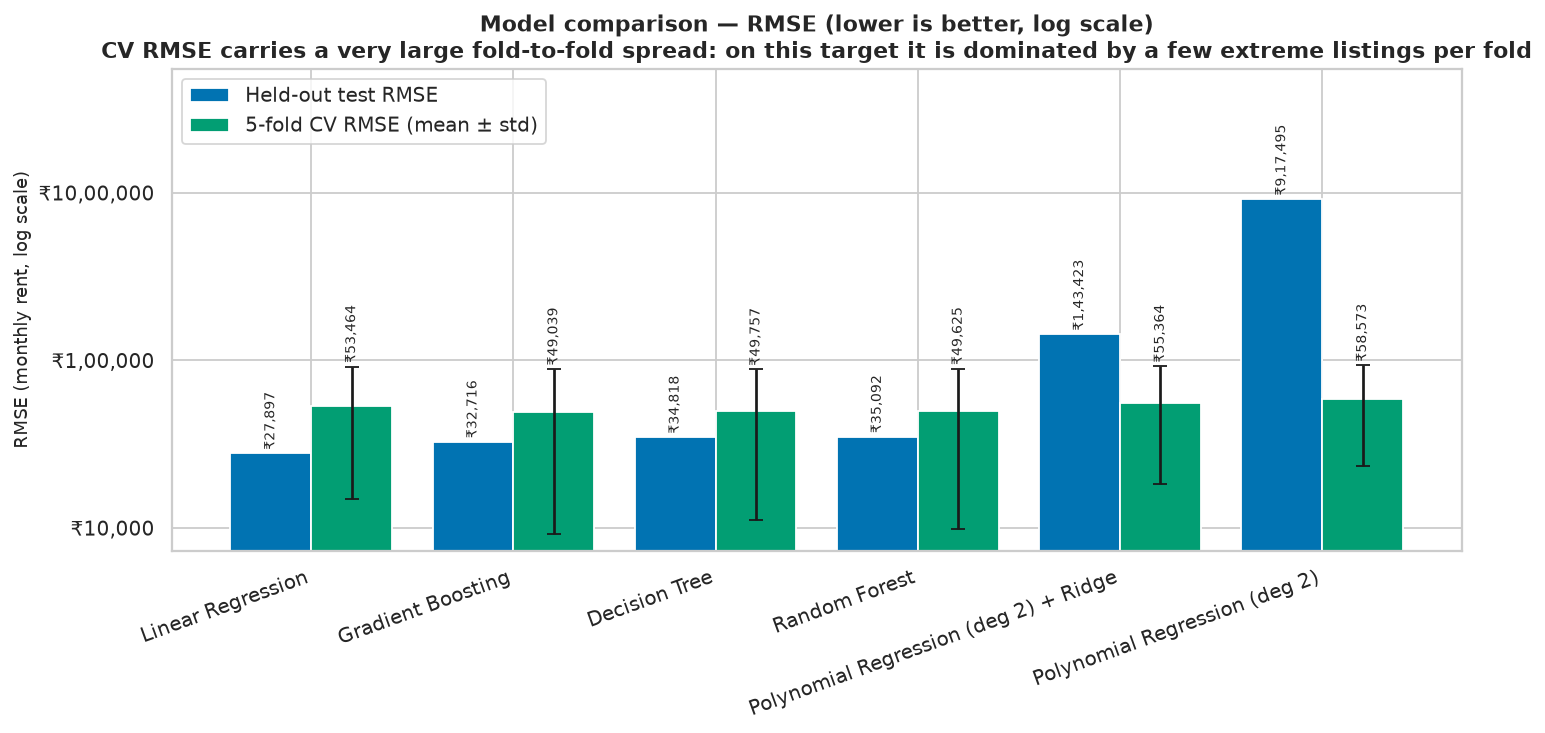

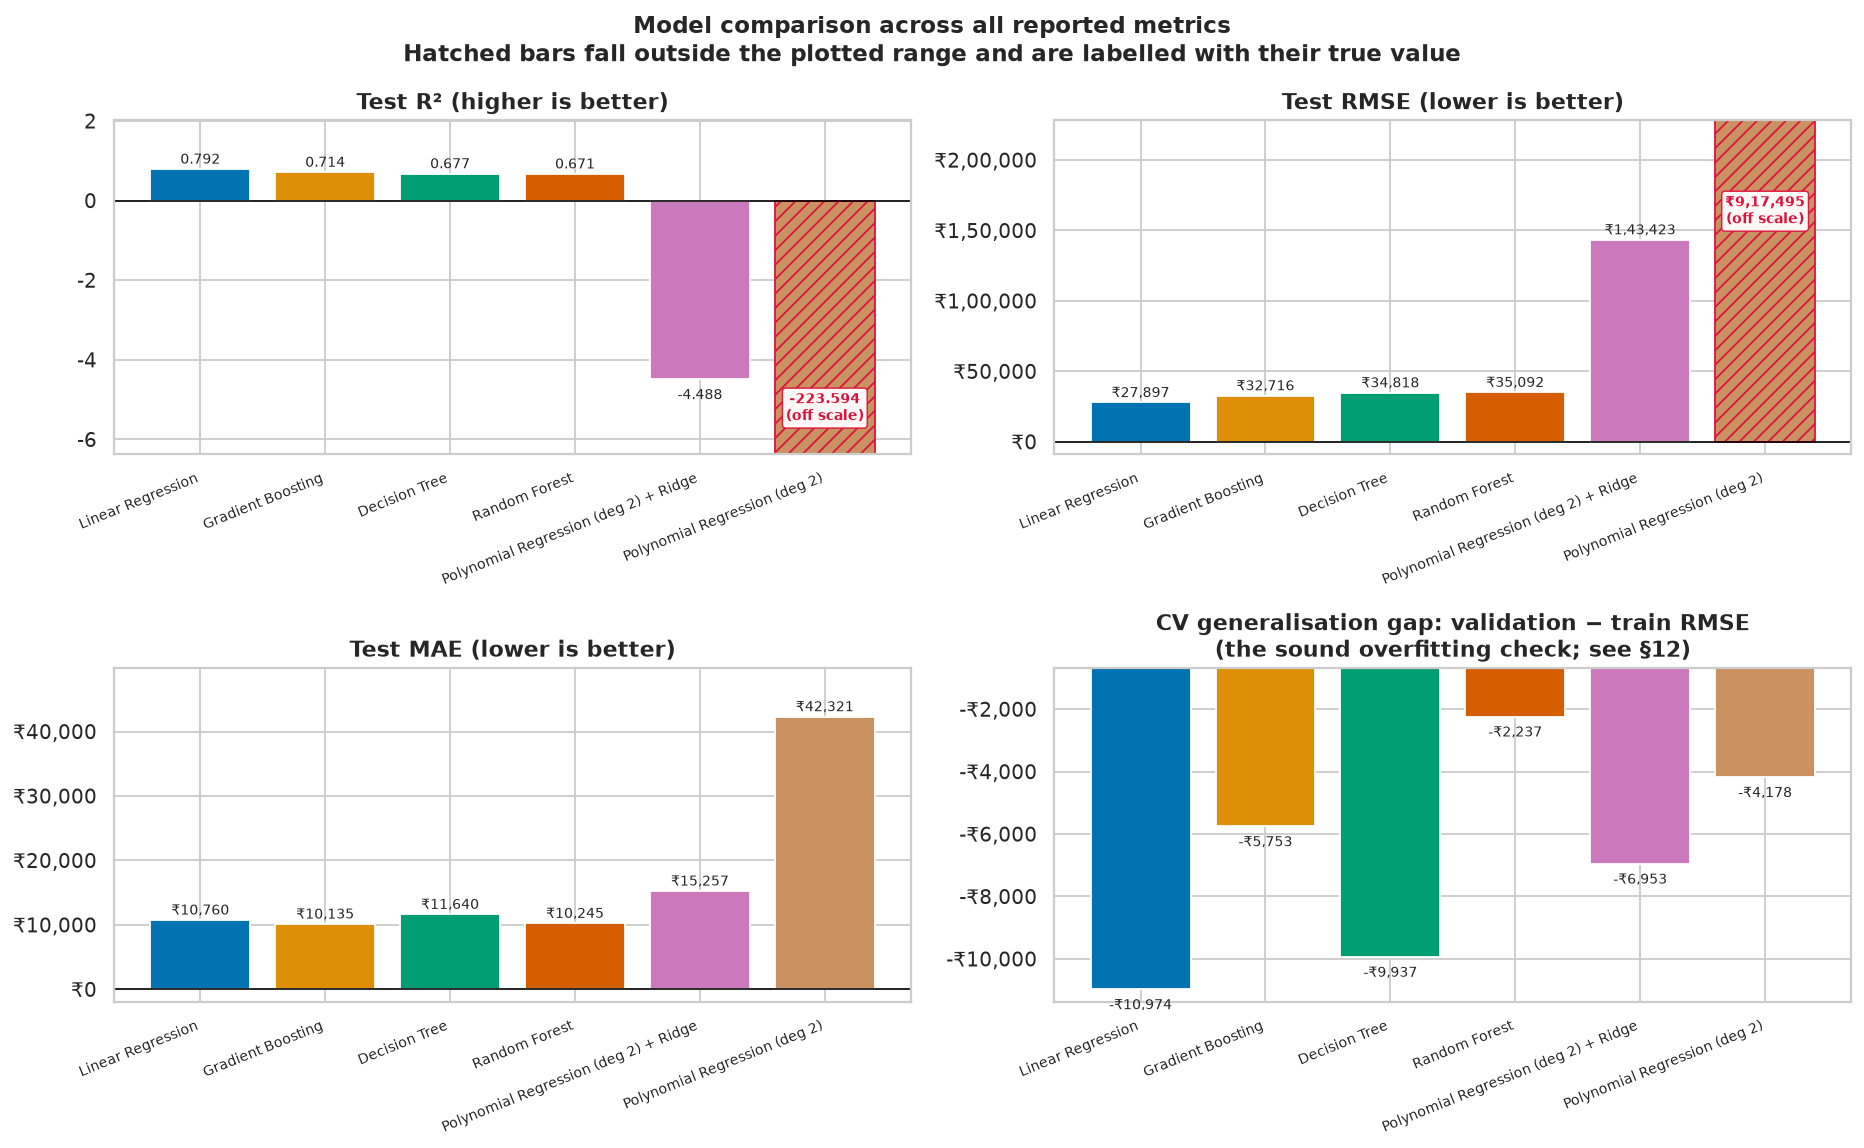

In [27]:
display(fig("model_rmse_comparison"))
display(fig("model_metric_panel"))

In [28]:
notes = table(M["model_comparison"], ["model", "note", "best_params"])
for _, row in notes.iterrows():
    display(Markdown(f"**{row['model']}** — {row['note']}"
                     + (f"  \n*Tuned:* `{row['best_params']}`"
                        if row.get("best_params") else "")))

**Linear Regression** — Baseline. No hyperparameters to tune, by design.

**Polynomial Regression (deg 2)** — Plain degree-2 expansion, no regularisation. Expands ~24 encoded features into ~324 correlated terms, so it is expected to overfit.

**Polynomial Regression (deg 2) + Ridge** — Same expansion with L2 shrinkage, which controls the collinearity the plain version suffers from.

**Decision Tree** — Single tree; interpretable but high variance.

**Random Forest** — Bagged trees; strong default performance, low variance.

**Gradient Boosting** — Sequential boosting; usually the strongest on tabular data.

## 6. Residual plots — for **all** models

The case study lists *Residual Plot* as a comparison metric, not merely a
best-model diagnostic, so all six models appear side by side on shared axes.

What to look for: residuals should scatter randomly around the zero line. A
visible funnel means error grows with predicted rent; curvature means the model
is missing a non-linear relationship; a solid band of points pinned at one
prediction level means the model has collapsed towards the mean.

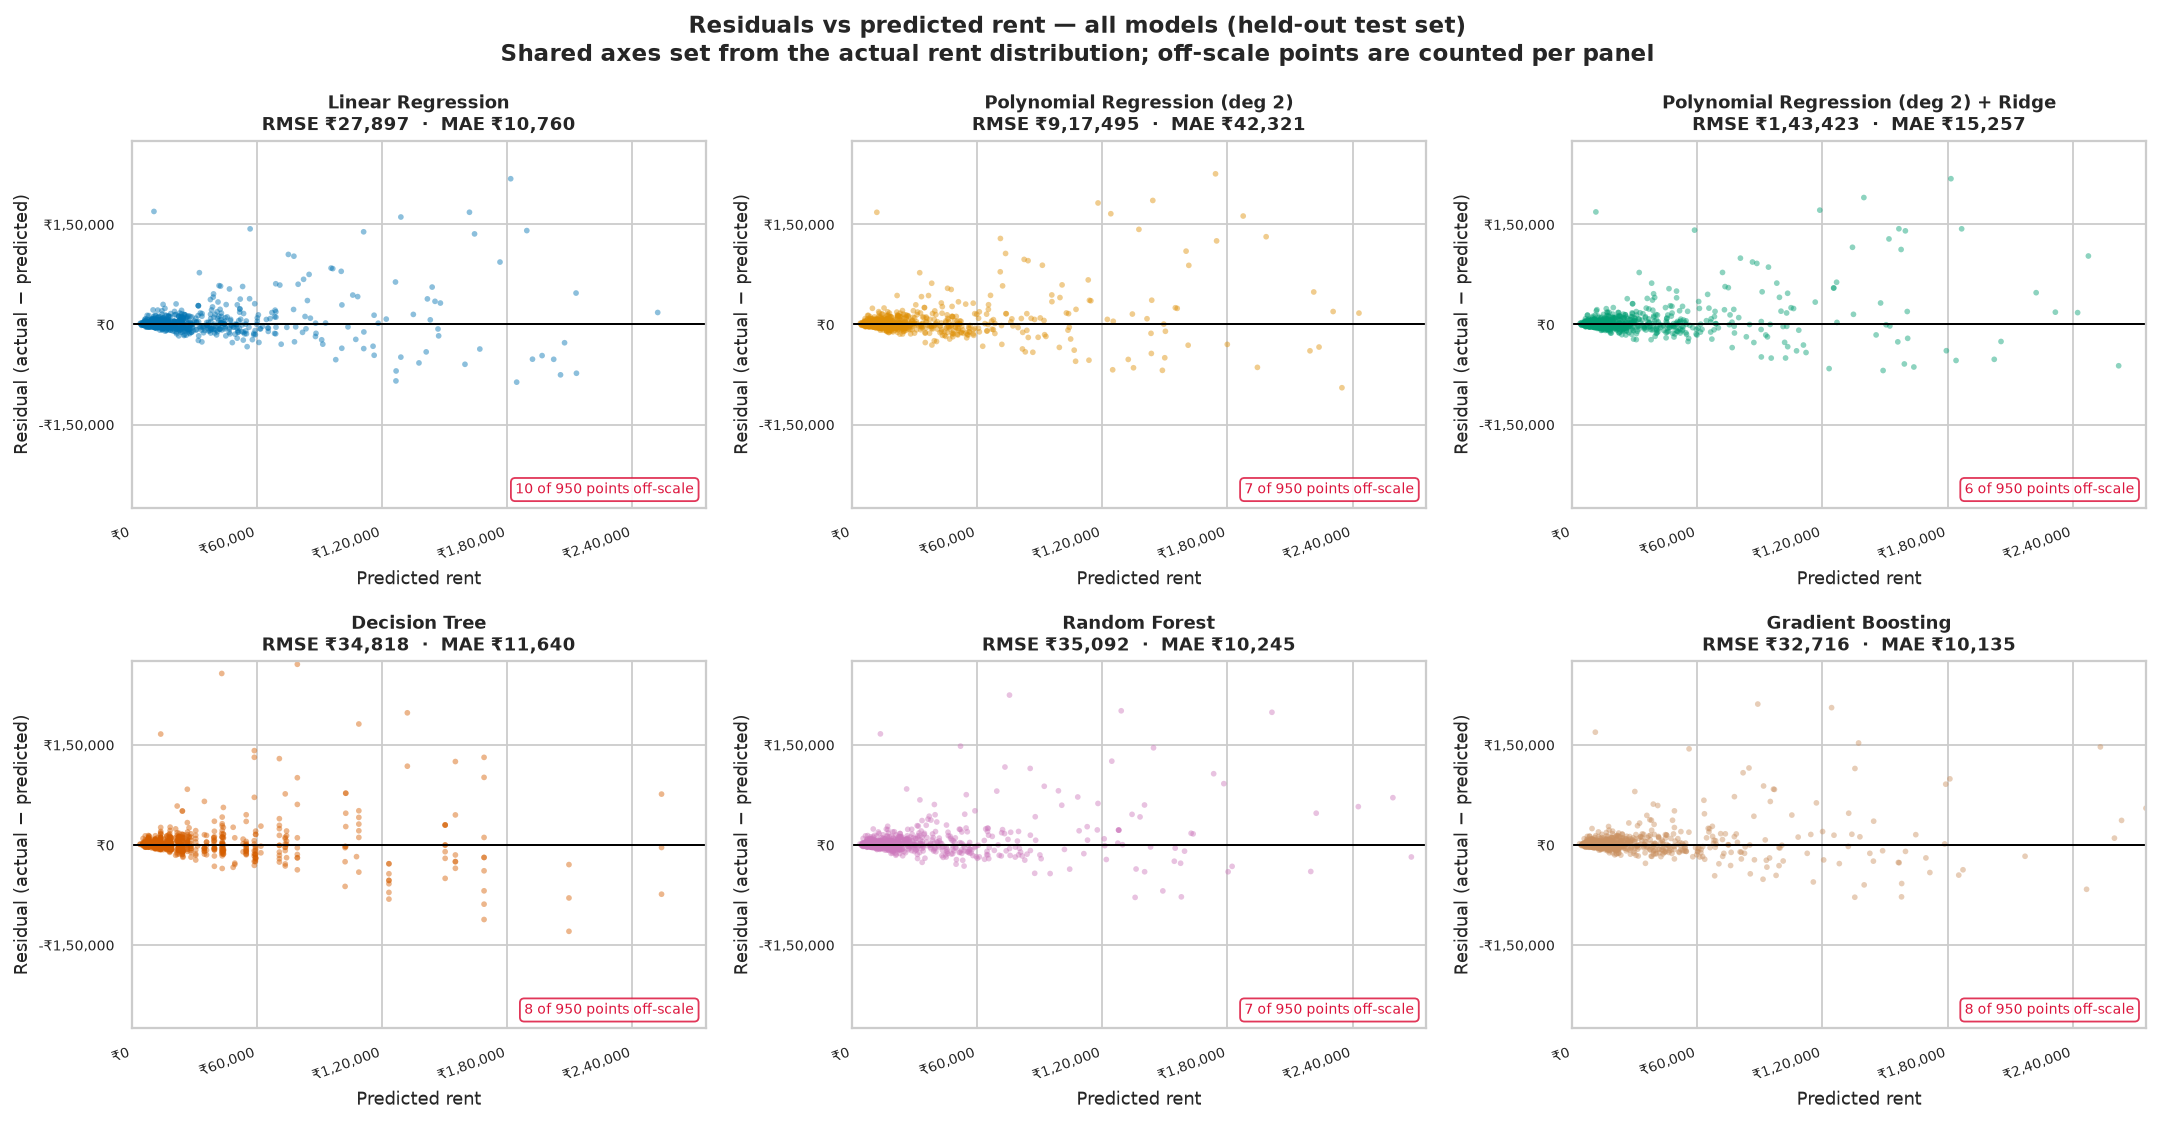

In [29]:
display(fig("residuals_all_models"))

## 7. The outlier experiment — the core comparative study

Every model is run under four settings:

1. **Raw rent target, no outlier treatment** — the naive baseline
2. **`log1p` target only**
3. **`log1p` + outliers removed** (per-city IQR)
4. **`log1p` + outliers capped** (winsorized at the per-city 1st/99th percentiles)

### The fairness requirement

Outlier treatment is applied to the **training split only**, and every
configuration is scored on the **same untreated held-out test set**. This matters
more than it might appear: if outliers were removed from the test set too, the
metrics would improve simply because the test set got easier, and the comparison
would be meaningless.

In [30]:
exp = table(M["outlier_experiment"])
pivot_rmse = exp.pivot(index="model", columns="setting", values="test_rmse")
pivot_mae = exp.pivot(index="model", columns="setting", values="test_mae")
pivot_r2 = exp.pivot(index="model", columns="setting", values="test_r2")

display(Markdown("#### Test RMSE (rupees) — lower is better"))
display(pivot_rmse.round(0))
display(Markdown("#### Test MAE (rupees) — lower is better"))
display(pivot_mae.round(0))
display(Markdown("#### Test R² — higher is better"))
display(pivot_r2.round(4))

#### Test RMSE (rupees) — lower is better

setting,"1. Raw rent, no treatment",2. log1p target only,3a. log1p + outliers removed,3b. log1p + outliers capped
model,,,,
Decision Tree,40920.0,34818.0,46731.0,35788.0
Gradient Boosting,35200.0,32716.0,46436.0,35025.0
Linear Regression,39566.0,27897.0,33198.0,29242.0
Polynomial Regression (deg 2),36384.0,917495.0,41111.0,155554.0
Polynomial Regression (deg 2) + Ridge,31502.0,143423.0,49427.0,46745.0
Random Forest,34796.0,35092.0,46609.0,35470.0


#### Test MAE (rupees) — lower is better

setting,"1. Raw rent, no treatment",2. log1p target only,3a. log1p + outliers removed,3b. log1p + outliers capped
model,,,,
Decision Tree,12789.0,11640.0,13457.0,11280.0
Gradient Boosting,11006.0,10135.0,12504.0,10447.0
Linear Regression,16668.0,10760.0,11334.0,10795.0
Polynomial Regression (deg 2),15116.0,42321.0,12056.0,15647.0
Polynomial Regression (deg 2) + Ridge,12470.0,15257.0,12870.0,11218.0
Random Forest,11334.0,10245.0,12706.0,10204.0


#### Test R² — higher is better

setting,"1. Raw rent, no treatment",2. log1p target only,3a. log1p + outliers removed,3b. log1p + outliers capped
model,,,,
Decision Tree,0.5532,0.6766,0.4174,0.6583
Gradient Boosting,0.6694,0.7144,0.4247,0.6727
Linear Regression,0.5823,0.7924,0.7060,0.7719
Polynomial Regression (deg 2),0.6468,-223.5945,0.5491,-5.4559
Polynomial Regression (deg 2) + Ridge,0.7352,-4.4882,0.3482,0.4170
Random Forest,0.6770,0.6714,0.4204,0.6643


> **How to read the CV columns in `reports/outlier_experiment.csv`.** They are
> **not comparable across settings**. Each setting cross-validates a *different*
> training set: under `remove`, the hard rows have been deleted from the folds
> themselves, so its CV RMSE looks dramatically better while the model has not
> improved at all. Only the `test_*` columns are comparable, because every row is
> scored on the one shared untreated test set. This is precisely the trap the
> fairness protocol above is designed to expose.

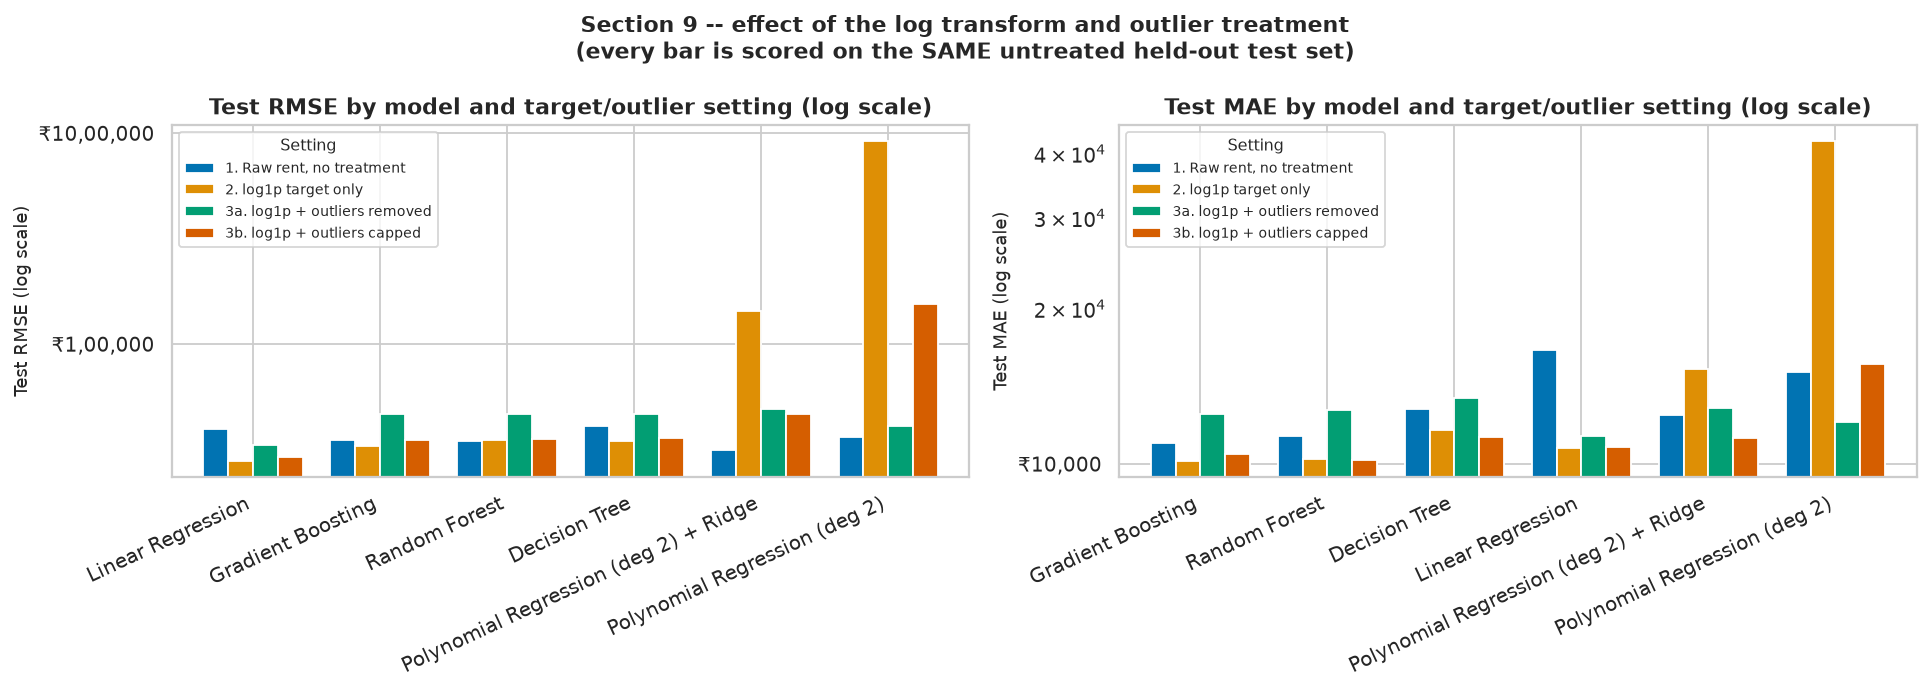

In [31]:
display(fig("outlier_experiment"))

#### MAE within rent bands — Gradient Boosting

setting,test listings,"1. Raw rent, no treatment",2. log1p target only,3a. log1p + outliers removed,3b. log1p + outliers capped
rent_band,,,,,
"< ₹15,000",415,3539.0,2528.0,2482.0,2524.0
"> ₹1,00,000 (premium)",64,70554.0,73887.0,105137.0,79468.0
"₹15,000 – ₹40,000",330,5843.0,5345.0,5067.0,5279.0
"₹40,000 – ₹1,00,000",141,18036.0,14798.0,17360.0,14531.0


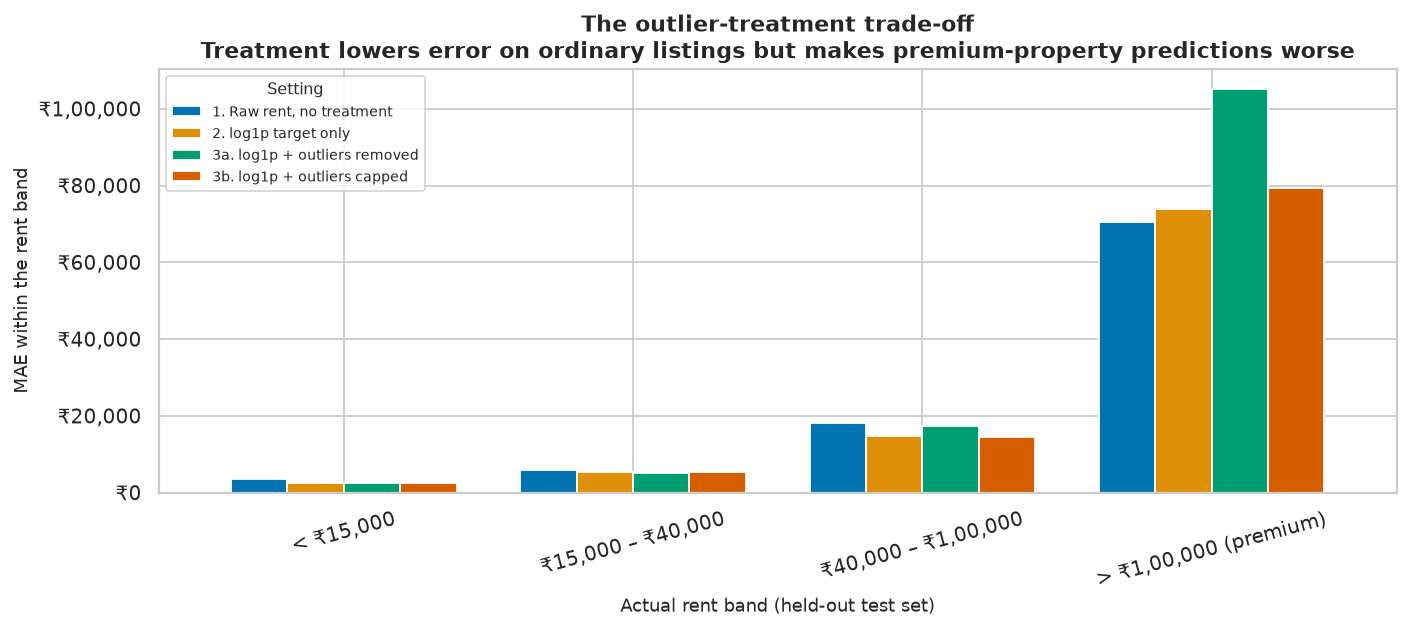

In [32]:
tr = table(M["premium_tradeoff"])
band_pivot = tr.pivot(index="rent_band", columns="setting", values="mae")
n_per_band = tr.groupby("rent_band")["n"].first()
band_pivot.insert(0, "test listings", n_per_band)
display(Markdown(f"#### MAE within rent bands — {best['name']}"))
display(band_pivot.round(0))
display(fig("outlier_premium_tradeoff"))

In [33]:
# The section-9 conclusion, written from the numbers actually obtained.
raw = exp[exp.setting_key == "raw_none"].set_index("model_key")
logo = exp[exp.setting_key == "log_none"].set_index("model_key")
rem = exp[exp.setting_key == "log_remove"].set_index("model_key")
cap = exp[exp.setting_key == "log_cap"].set_index("model_key")
k = best["key"]

premium_band = [b for b in band_pivot.index if "premium" in str(b)][0]
cheap_band = list(band_pivot.index)[0]
cols = {c.split(".")[0].strip(): c for c in band_pivot.columns if c != "test listings"}
c_log = [c for c in band_pivot.columns if "log1p target only" in str(c)][0]
c_rem = [c for c in band_pivot.columns if "removed" in str(c)][0]

display(Markdown(f'''
### Conclusion — the effect of outlier treatment

**1. The log transform is the single biggest win, and it is unambiguous.**
For {best["name"]}, moving from a raw target to `log1p` changes test RMSE from
**{format_inr(raw.loc[k, "test_rmse"])}** to **{format_inr(logo.loc[k, "test_rmse"])}**
and test MAE from **{format_inr(raw.loc[k, "test_mae"])}** to
**{format_inr(logo.loc[k, "test_mae"])}**. Training on raw rupees lets a handful of
listings dominate the squared-error objective; the log scale makes the model fit
the other 99%.

**2. Outlier treatment improves the typical listing and damages the expensive one.**
This is the trade-off the case study asks about, and the banded table above is
where it is visible. In the cheapest band ({cheap_band}) removal
{"lowers" if band_pivot.loc[cheap_band, c_rem] < band_pivot.loc[cheap_band, c_log] else "raises"}
MAE from {format_inr(band_pivot.loc[cheap_band, c_log])} to
{format_inr(band_pivot.loc[cheap_band, c_rem])}. In the premium band
({premium_band}) it moves MAE from {format_inr(band_pivot.loc[premium_band, c_log])}
to **{format_inr(band_pivot.loc[premium_band, c_rem])}**.

The mechanism is simple: a model trained with the expensive listings deleted has
never seen a flat of that kind, so it regresses premium properties towards the
ordinary market and under-predicts them systematically.

**3. Overall RMSE therefore moves the opposite way to overall MAE.**
RMSE squares errors, so it is dominated by the premium listings that treatment
makes worse; MAE weights every listing equally, so it reflects the majority that
treatment makes better. Reporting only one of them would tell half the story —
which is why both are reported for every configuration.

**4. Capping is the gentler option.** Winsorizing keeps every row and only pulls
extreme rents inwards, so the model still sees that expensive properties exist.
Removal discards the evidence entirely.

**Decision.** The deployed model is trained under **{best["setting_label"]}**,
which achieved the lowest test RMSE on the untreated test set. The premium-band
caveat is carried through to the Limitations section and is surfaced in the
Streamlit app rather than hidden.
'''))


### Conclusion — the effect of outlier treatment

**1. The log transform is the single biggest win, and it is unambiguous.**
For Gradient Boosting, moving from a raw target to `log1p` changes test RMSE from
**₹35,200** to **₹32,716**
and test MAE from **₹11,006** to
**₹10,135**. Training on raw rupees lets a handful of
listings dominate the squared-error objective; the log scale makes the model fit
the other 99%.

**2. Outlier treatment improves the typical listing and damages the expensive one.**
This is the trade-off the case study asks about, and the banded table above is
where it is visible. In the cheapest band (< ₹15,000) removal
lowers
MAE from ₹2,528 to
₹2,482. In the premium band
(> ₹1,00,000 (premium)) it moves MAE from ₹73,887
to **₹1,05,137**.

The mechanism is simple: a model trained with the expensive listings deleted has
never seen a flat of that kind, so it regresses premium properties towards the
ordinary market and under-predicts them systematically.

**3. Overall RMSE therefore moves the opposite way to overall MAE.**
RMSE squares errors, so it is dominated by the premium listings that treatment
makes worse; MAE weights every listing equally, so it reflects the majority that
treatment makes better. Reporting only one of them would tell half the story —
which is why both are reported for every configuration.

**4. Capping is the gentler option.** Winsorizing keeps every row and only pulls
extreme rents inwards, so the model still sees that expensive properties exist.
Removal discards the evidence entirely.

**Decision.** The deployed model is trained under **2. log1p target only**,
which achieved the lowest test RMSE on the untreated test set. The premium-band
caveat is carried through to the Limitations section and is surfaced in the
Streamlit app rather than hidden.


## 8. Deep residual analysis — the selected model

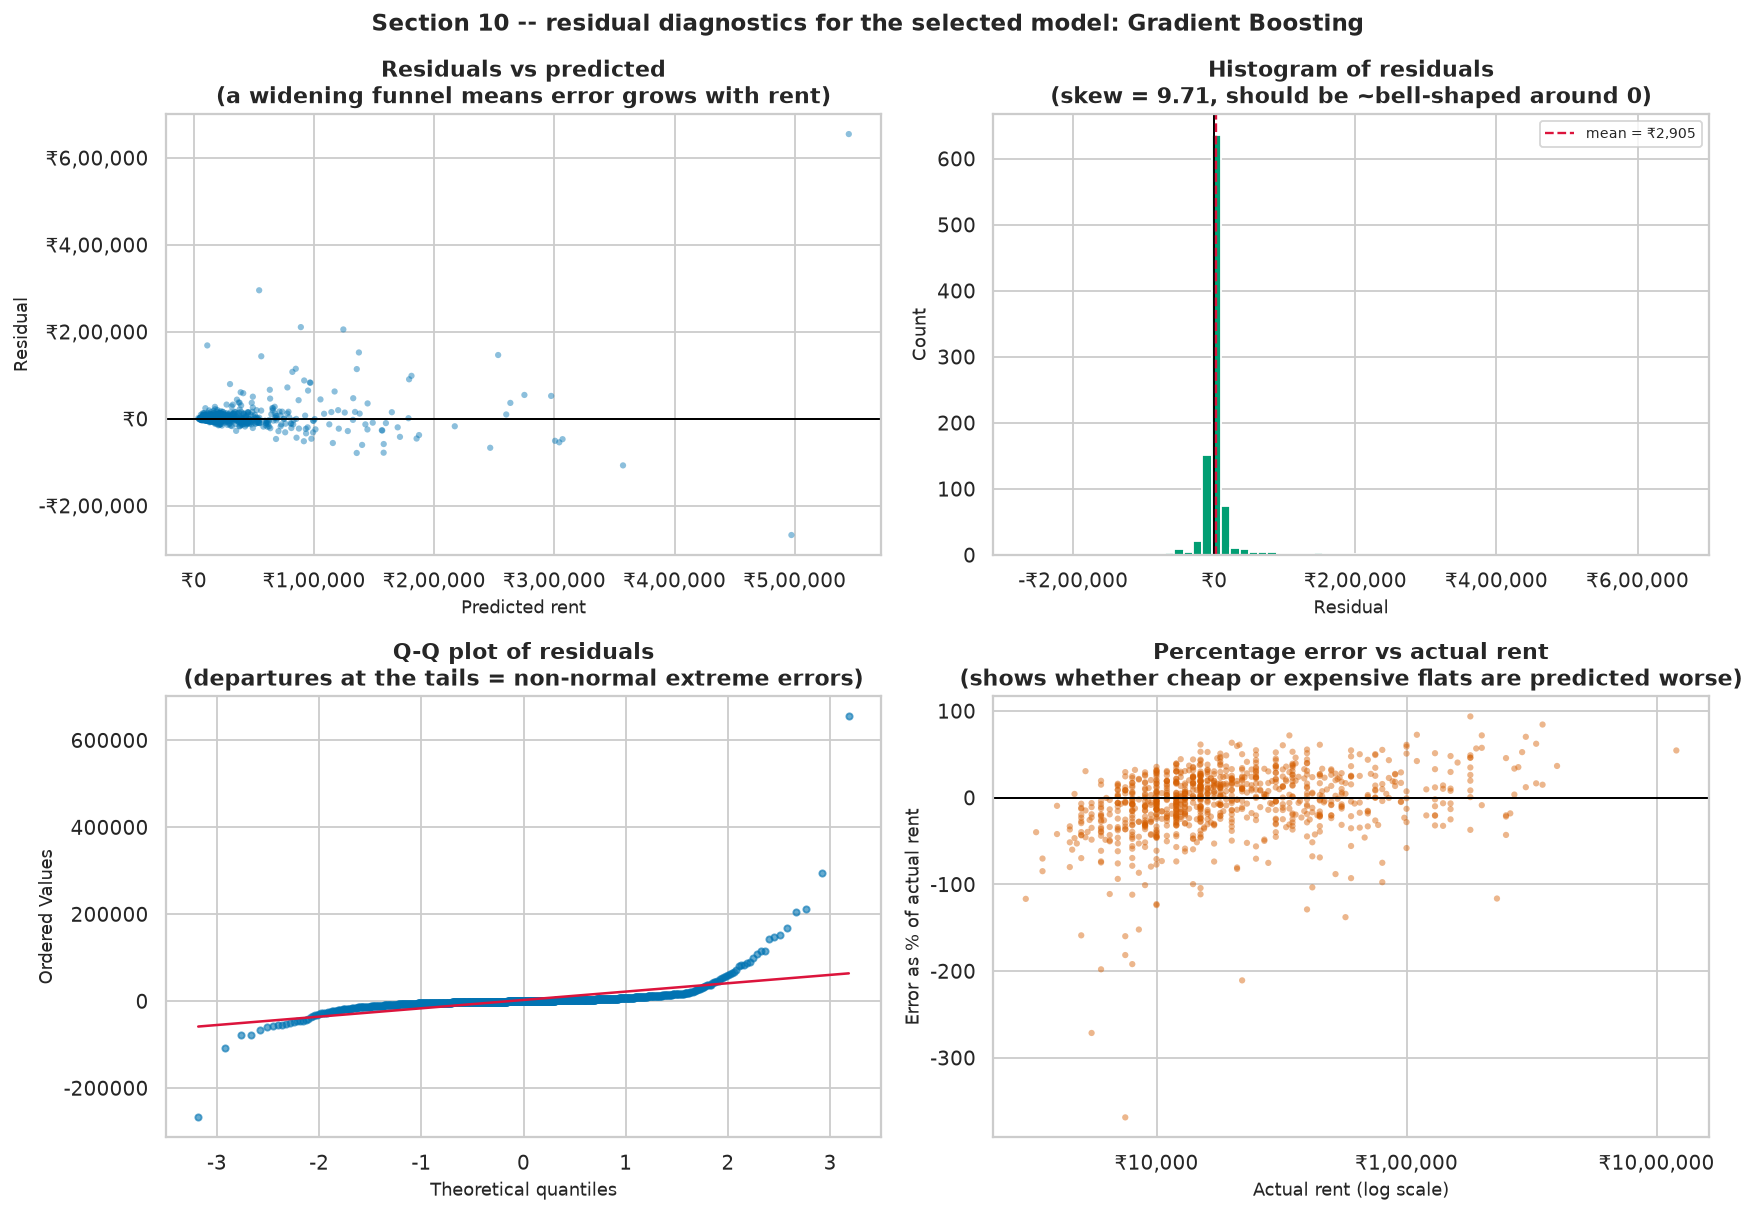


| diagnostic | value | reading |
|---|---|---|
| mean residual | ₹2,905 | close to zero — no systematic bias |
| median residual | -₹38 | the typical listing |
| residual skew | 9.71 | heavy-tailed — a few large misses dominate |
| residual kurtosis | 185.09 | far above the normal value of 0 — extreme errors are much more common than a bell curve predicts |
| corr(predicted, abs error) | 0.642 | **clear funnel** — absolute error grows with predicted rent |
| within ±10% of actual | 25.5% of test listings | |
| within ±25% of actual | 59.9% of test listings | |

**Interpretation.** The funnel is expected and is not a defect: the model was
trained on `log1p(Rent)`, so it controls *proportional* error, and a constant
percentage error necessarily becomes a larger rupee error at higher rents. The
percentage-error panel (bottom right) is the honest view.

The Q-Q plot bends away from the line at both tails, confirming that the extreme
errors are not normally distributed. Squared-error metrics such as RMSE are
therefore dominated by those tails, which is why MAE and MAPE are reported
alongside.


In [34]:
rs = M["residual_stats"]
display(fig("best_model_residuals"))
display(Markdown(f'''
| diagnostic | value | reading |
|---|---|---|
| mean residual | {format_inr(rs["mean"])} | {"close to zero — no systematic bias" if abs(rs["mean"]) < 3000 else "non-zero — the model is systematically biased"} |
| median residual | {format_inr(rs["median"])} | the typical listing |
| residual skew | {rs["skew"]:.2f} | {"roughly symmetric" if abs(rs["skew"]) < 1 else "heavy-tailed — a few large misses dominate"} |
| residual kurtosis | {rs["kurtosis"]:.2f} | {"far above the normal value of 0 — extreme errors are much more common than a bell curve predicts" if rs["kurtosis"] > 3 else "close to normal"} |
| corr(predicted, abs error) | {rs["funnel_corr_pred_vs_abs_error"]:.3f} | {"**clear funnel** — absolute error grows with predicted rent" if rs["funnel_corr_pred_vs_abs_error"] > 0.3 else "little funnel effect in absolute terms"} |
| within ±10% of actual | {rs["pct_within_10pct"]:.1f}% of test listings | |
| within ±25% of actual | {rs["pct_within_25pct"]:.1f}% of test listings | |

**Interpretation.** The funnel is expected and is not a defect: the model was
trained on `log1p(Rent)`, so it controls *proportional* error, and a constant
percentage error necessarily becomes a larger rupee error at higher rents. The
percentage-error panel (bottom right) is the honest view.

The Q-Q plot bends away from the line at both tails, confirming that the extreme
errors are not normally distributed. Squared-error metrics such as RMSE are
therefore dominated by those tails, which is why MAE and MAPE are reported
alongside.
'''))

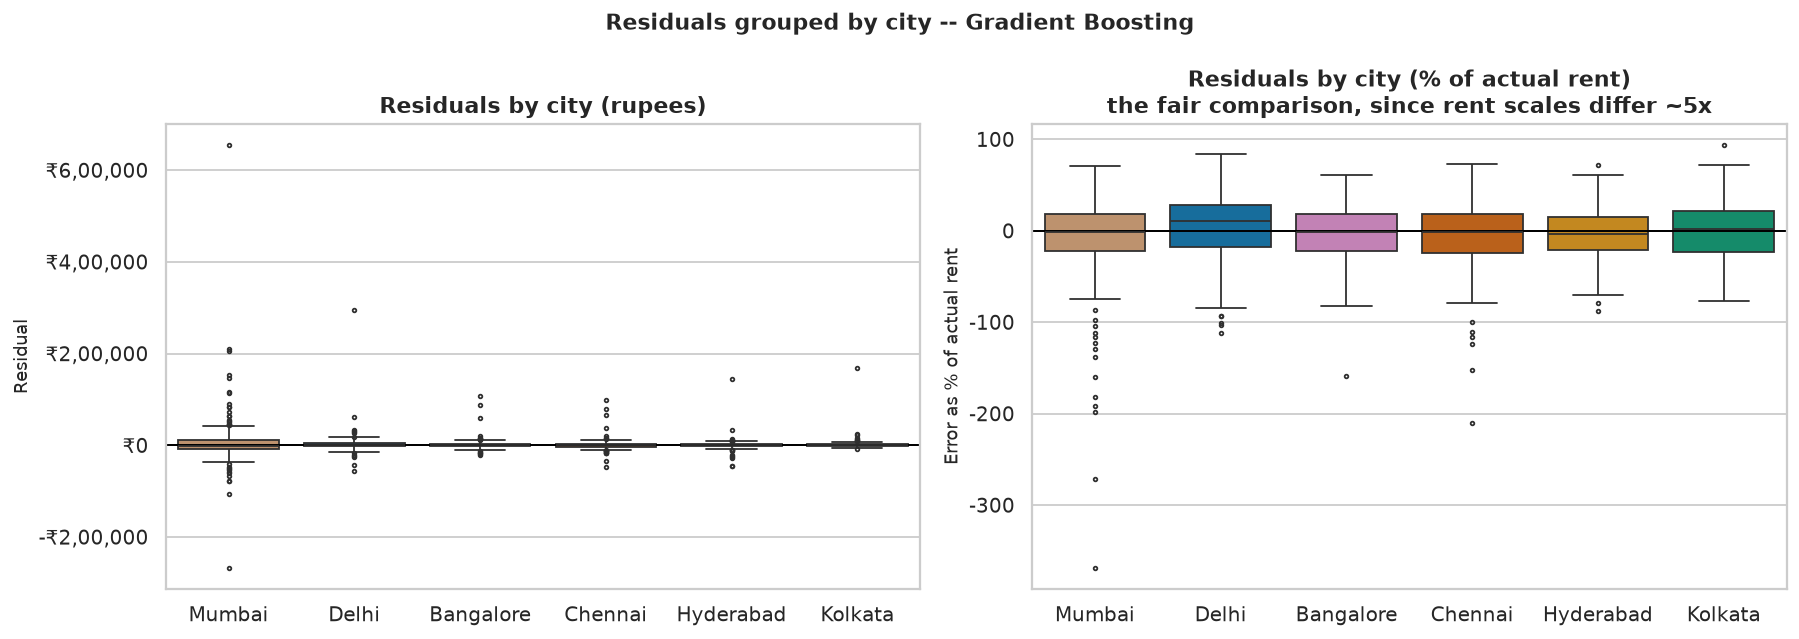

In [35]:
display(fig("best_model_residuals_by_city"))

### Why RMSE is reported but not ranked on

RMSE squares the errors, so on a target this heavy-tailed a handful of listings
can decide the entire ranking of models.

In [36]:
conc = M["error_concentration"]
rows = [{"worst k test rows": k,
         "share of total MSE": conc[f"top_{k}_share_of_mse"]}
        for k in (1, 2, 5, 10, 20, 50) if f"top_{k}_share_of_mse" in conc]
display(pd.DataFrame(rows).style.format({"share of total MSE": "{:.1%}"}))
display(Markdown(f'''
Of {conc["n_rows"]} test listings, the **single worst prediction alone accounts
for {conc["top_1_share_of_mse"]:.0%} of total MSE**, and the worst 10 account for
**{conc["top_10_share_of_mse"]:.0%}**.

* RMSE over all rows: **{format_inr(conc["rmse_all"])}**
* RMSE excluding the worst 1% of rows: **{format_inr(conc["rmse_excluding_worst_1pct"])}**

So test RMSE is largely a measurement of how well a model handles a few premium
listings, not of its general accuracy. That is a legitimate thing to care about —
and it is exactly why the specification asks for the outlier experiment — but it
makes RMSE a poor metric to *rank* models on, because the ranking can be flipped
by one listing. MAE and MAPE are reported alongside for that reason, and the model
selection in section 10 ranks on several criteria rather than on RMSE alone.
'''))

,worst k test rows,share of total MSE
0,1,42.2%
1,2,50.8%
2,5,66.4%
3,10,76.9%
4,20,85.6%
5,50,94.2%



Of 950 test listings, the **single worst prediction alone accounts
for 42% of total MSE**, and the worst 10 account for
**77%**.

* RMSE over all rows: **₹32,716**
* RMSE excluding the worst 1% of rows: **₹16,234**

So test RMSE is largely a measurement of how well a model handles a few premium
listings, not of its general accuracy. That is a legitimate thing to care about —
and it is exactly why the specification asks for the outlier experiment — but it
makes RMSE a poor metric to *rank* models on, because the ranking can be flipped
by one listing. MAE and MAPE are reported alongside for that reason, and the model
selection in section 10 ranks on several criteria rather than on RMSE alone.


### The ten worst predictions

In [37]:
worst = table(M["worst_predictions"])
show = worst[["City", "Area Locality", "BHK", "Size", "actual_rent",
              "predicted_rent", "pct_error", "locality_count_in_train",
              "direction"]].copy()
show.columns = ["City", "Locality", "BHK", "Size", "Actual", "Predicted",
                "Error %", "Locality rows in train", "Direction"]
display(show.round(1))
display(Markdown("#### Why each one failed\n\n" + "\n".join(
    f"{i + 1}. **{r['City']} — {r['Area Locality']}**, {r['BHK']} BHK, "
    f"{r['Size']:.0f} sq ft. Actual {format_inr(r['actual_rent'])}, predicted "
    f"{format_inr(r['predicted_rent'])} ({r['pct_error']:+.0f}%). {r['why']}"
    for i, r in worst.iterrows())))

,City,Locality,BHK,Size,Actual,Predicted,Error %,Locality rows in train,Direction
0,Mumbai,Juhu,4,5000,1200000.0,544973.4,-54.6,3,under-predicted
1,Delhi,Green Park,4,800,350000.0,54297.9,-84.5,1,under-predicted
2,Mumbai,"Lake Superior, Powai",4,3700,230000.0,497219.1,116.2,0,over-predicted
3,Mumbai,"Chaitanya Towers, Prabhadevi",3,1600,300000.0,88989.5,-70.3,1,under-predicted
4,Mumbai,"Indiabulls Blu, Worli",3,1500,330000.0,124352.9,-62.3,2,under-predicted
5,Kolkata,"Avenue S, Santoshpur",2,950,180000.0,11128.2,-93.8,0,under-predicted
6,Mumbai,"Benchmark Solus, Waterfield Road",4,1500,290000.0,137300.7,-52.7,0,under-predicted
7,Mumbai,Pali Hill,3,1800,400000.0,253177.0,-36.7,1,under-predicted
8,Hyderabad,"Beeramguda, Ramachandra Puram, NH 9",1,8000,200000.0,56061.6,-72.0,0,under-predicted
9,Mumbai,Union Park,2,1000,200000.0,84773.4,-57.6,0,under-predicted


#### Why each one failed

1. **Mumbai — Juhu**, 4 BHK, 5000 sq ft. Actual ₹12,00,000, predicted ₹5,44,973 (-55%). premium listing far above the local distribution; the log target deliberately down-weights these
2. **Delhi — Green Park**, 4 BHK, 800 sq ft. Actual ₹3,50,000, predicted ₹54,298 (-84%). locality appears only 1x in training -- target encoding is heavily smoothed towards the city average
3. **Mumbai — Lake Superior, Powai**, 4 BHK, 3700 sq ft. Actual ₹2,30,000, predicted ₹4,97,219 (+116%). locality unseen in training -- falls back to the city/global average
4. **Mumbai — Chaitanya Towers, Prabhadevi**, 3 BHK, 1600 sq ft. Actual ₹3,00,000, predicted ₹88,990 (-70%). locality appears only 1x in training -- target encoding is heavily smoothed towards the city average
5. **Mumbai — Indiabulls Blu, Worli**, 3 BHK, 1500 sq ft. Actual ₹3,30,000, predicted ₹1,24,353 (-62%). locality appears only 2x in training -- target encoding is heavily smoothed towards the city average
6. **Kolkata — Avenue S, Santoshpur**, 2 BHK, 950 sq ft. Actual ₹1,80,000, predicted ₹11,128 (-94%). locality unseen in training -- falls back to the city/global average
7. **Mumbai — Benchmark Solus, Waterfield Road**, 4 BHK, 1500 sq ft. Actual ₹2,90,000, predicted ₹1,37,301 (-53%). locality unseen in training -- falls back to the city/global average
8. **Mumbai — Pali Hill**, 3 BHK, 1800 sq ft. Actual ₹4,00,000, predicted ₹2,53,177 (-37%). locality appears only 1x in training -- target encoding is heavily smoothed towards the city average
9. **Hyderabad —  Beeramguda, Ramachandra Puram, NH 9**, 1 BHK, 8000 sq ft. Actual ₹2,00,000, predicted ₹56,062 (-72%). locality unseen in training -- falls back to the city/global average
10. **Mumbai — Union Park**, 2 BHK, 1000 sq ft. Actual ₹2,00,000, predicted ₹84,773 (-58%). locality unseen in training -- falls back to the city/global average

## 9. Feature importance and the locality ablation

Two importance measures are reported, because they disagree in an informative
way.

* **Impurity-based importance** is computed on the *encoded* columns and is
  biased towards high-cardinality features — the target-encoded locality has
  thousands of possible split points and is flattered by construction.
* **Permutation importance** is computed on the *original input columns* by
  shuffling each one and measuring how much worse the model gets on the held-out
  test set. It answers "which attribute matters", and it is the more reliable of
  the two.

,Feature,MAE increase when shuffled,± std,R² drop when shuffled
0,City,7289.925,584.608,0.340
1,Size,5506.207,440.538,0.330
2,Bathroom,2804.498,310.789,0.219
3,Point of Contact,2774.504,361.506,0.196
4,Area Locality,1997.793,248.640,0.091
5,Furnishing Status,334.021,88.721,0.002
6,BHK,278.781,42.023,0.004
7,Floor,243.881,71.756,-0.010
8,Area Type,146.316,160.012,0.007
9,Tenant Preferred,22.964,34.350,-0.001



**Why two scorers.** R² is the conventional choice for permutation importance,
but it is very unstable on this target: one extreme rent dominates the sum of
squares, so shuffling a column swings R² wildly — note that the R²-based standard
deviation for `Size` exceeds its own mean. The MAE-based measure is robust to
that, so the ranking above is taken from it.

**The two measures disagree, and the disagreement is the finding.** `Size` ranks
first by R² drop while `City` ranks first by MAE increase. That is not a
contradiction: R² is driven by the expensive listings, where floor area is what
separates a ₹2 lakh flat from a ₹5 lakh one, whereas MAE reflects the typical
listing, where which city you are in matters more than a few hundred square feet.


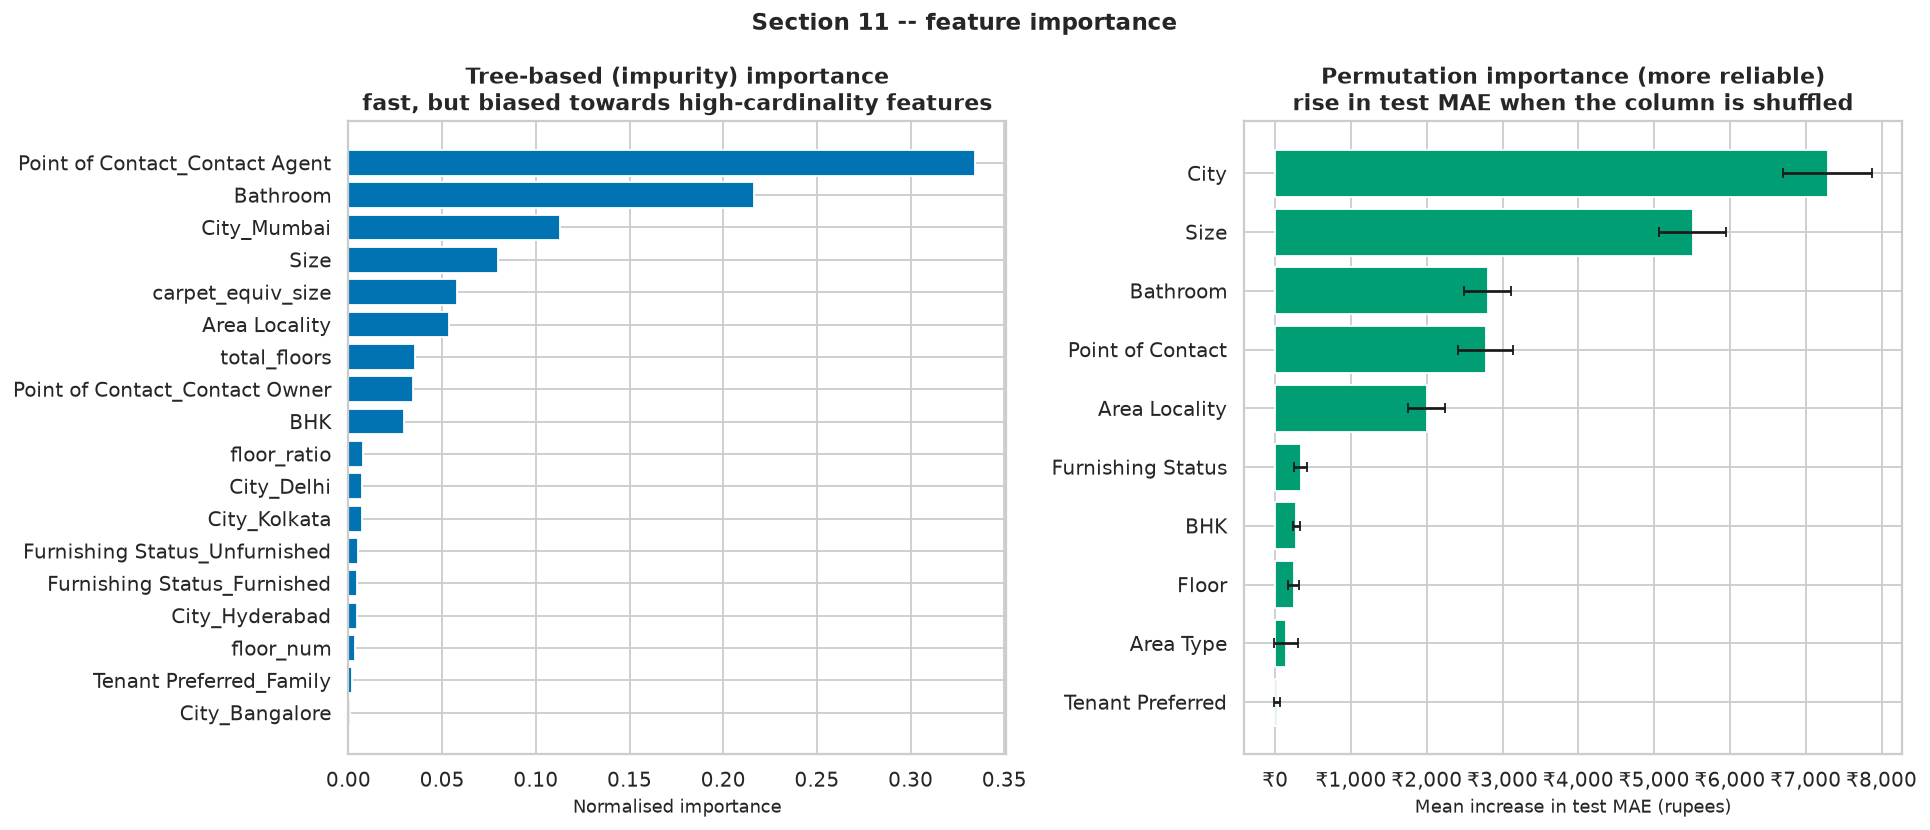

In [38]:
perm = table(M["feature_importance_permutation"])
show = perm[["feature", "importance_mean", "importance_std", "r2_drop_mean"]].copy()
show.columns = ["Feature", "MAE increase when shuffled", "± std", "R² drop when shuffled"]
display(show.round(3))
display(Markdown(f'''
**Why two scorers.** R² is the conventional choice for permutation importance,
but it is very unstable on this target: one extreme rent dominates the sum of
squares, so shuffling a column swings R² wildly — note that the R²-based standard
deviation for `Size` exceeds its own mean. The MAE-based measure is robust to
that, so the ranking above is taken from it.

**The two measures disagree, and the disagreement is the finding.** `Size` ranks
first by R² drop while `City` ranks first by MAE increase. That is not a
contradiction: R² is driven by the expensive listings, where floor area is what
separates a ₹2 lakh flat from a ₹5 lakh one, whereas MAE reflects the typical
listing, where which city you are in matters more than a few hundred square feet.
'''))
display(fig("feature_importance"))

In [39]:
tree_imp = table(M["feature_importance_tree"]).head(12)
display(Markdown("#### Impurity-based importance on the encoded columns (for contrast)"))
display(tree_imp.round(4))

#### Impurity-based importance on the encoded columns (for contrast)

,feature,importance
0,Point of Contact_Contact Agent,0.3342
1,Bathroom,0.2163
2,City_Mumbai,0.1131
3,Size,0.0799
4,carpet_equiv_size,0.0579
5,Area Locality,0.0537
6,total_floors,0.0358
7,Point of Contact_Contact Owner,0.0342
8,BHK,0.0295
9,floor_ratio,0.0077


### The ablation: does locality dominate the other predictors?

Three models, identical except for the feature set, each tuned independently and
scored on the same test set.

* **Model A** — all features
* **Model B** — without `Area Locality` and `City`
* **Model C** — only `Area Locality` and `City`

,Model,Test RMSE,Test MAE,Test R²,Test MAPE %
0,A: all features,32715.990,10134.771,0.714,26.744
1,B: without Locality and City,44727.847,13156.244,0.466,34.193
2,C: only Locality and City,47537.334,16514.484,0.397,51.496


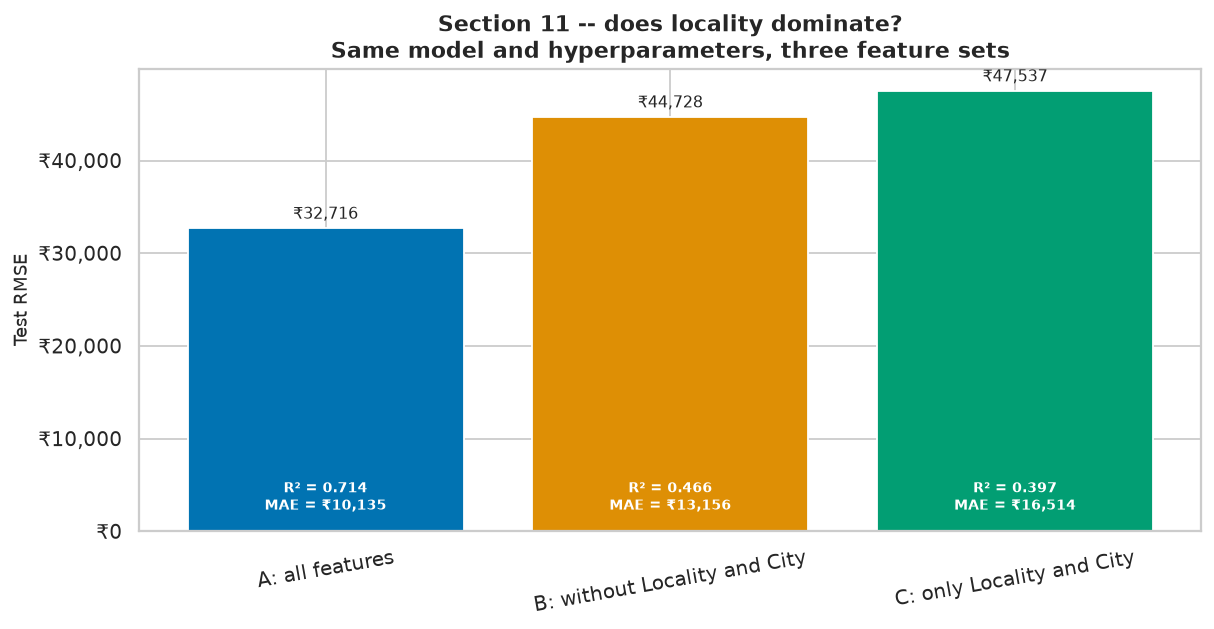


### Conclusion

Location is the single strongest block of predictors but it does NOT dominate on its own: location-only reaches R² 0.397 versus 0.714 for the full model, so the physical attributes (size, bathrooms, BHK, floor) still contribute materially. Equally, removing location costs 36.7% RMSE, so neither block is redundant.

Read precisely:

* Removing location costs **36.7% RMSE**
  (R² 0.714 → 0.466). Location is clearly the strongest
  single block of predictors.
* But location *alone* reaches only R² **0.397** against
  **0.714** for the full model — about
  **56%** of the explained variance. The
  physical attributes (size, bathrooms, BHK, floor) carry the rest.

So the answer to *"does locality dominate?"* is **no, not on its own** — knowing
where a flat is tells you more than any other single fact about it, but you still
need to know how big it is. Neither block is redundant.

*Caveat.* Model B still uses `City` inside the imputation step (to fill the 16
implausible `Size` values from a `(City, BHK)` median), so its handicap is very
slightly understated. The effect touches 16 of 3,796 training rows
and does not change the conclusion.


In [40]:
ab = table(M["ablation"])
show = ab[["label", "test_rmse", "test_mae", "test_r2", "test_mape"]].copy()
show.columns = ["Model", "Test RMSE", "Test MAE", "Test R²", "Test MAPE %"]
display(show.round(3))
display(fig("locality_ablation"))

a, b, c = ab.iloc[0], ab.iloc[1], ab.iloc[2]
display(Markdown(f'''
### Conclusion

{M["ablation_conclusion"]}

Read precisely:

* Removing location costs **{(b["test_rmse"] - a["test_rmse"]) / a["test_rmse"] * 100:.1f}% RMSE**
  (R² {a["test_r2"]:.3f} → {b["test_r2"]:.3f}). Location is clearly the strongest
  single block of predictors.
* But location *alone* reaches only R² **{c["test_r2"]:.3f}** against
  **{a["test_r2"]:.3f}** for the full model — about
  **{c["test_r2"] / a["test_r2"] * 100:.0f}%** of the explained variance. The
  physical attributes (size, bathrooms, BHK, floor) carry the rest.

So the answer to *"does locality dominate?"* is **no, not on its own** — knowing
where a flat is tells you more than any other single fact about it, but you still
need to know how big it is. Neither block is redundant.

*Caveat.* Model B still uses `City` inside the imputation step (to fill the 16
implausible `Size` values from a `(City, BHK)` median), so its handicap is very
slightly understated. The effect touches 16 of {split["n_train"]:,} training rows
and does not change the conclusion.
'''))

## 10. Model selection justification

Selecting on RMSE alone is not enough — a model can win on RMSE while being
unstable across folds, badly overfitted, or too slow to serve. On this dataset
there is a sharper reason still: section 8 showed that a handful of test listings
decide RMSE outright, so an RMSE-only ranking can be flipped by one property.

Candidates are therefore shortlisted on **test MAE** and then ranked across four
criteria at once — test MAE, test RMSE, the cross-validated generalisation gap,
and CV stability — with interpretability and prediction speed discussed
explicitly below.

In [41]:
sel = table(M["selection_table"])
# Renamed by key rather than by position, so adding a column upstream cannot
# silently misalign the headings.
show = sel.rename(columns={
    "model": "Model", "test_rmse": "Test RMSE", "test_mae": "Test MAE",
    "test_r2": "Test R²", "test_mape": "Test MAPE %",
    "overfit_gap_rmse": "Train→test RMSE gap",
    "cv_overfit_gap_rmse": "CV gap (val − train)",
    "cv_rmse_mean": "CV RMSE", "cv_rmse_std": "CV RMSE std",
    "cv_mae_std": "CV MAE std", "predict_latency_ms": "Latency (ms)",
})
display(show.round(3))
display(Markdown(f"**Shortlist** (within 10% of the best test MAE): "
                 f"{', '.join(M['shortlist'])}"))

rank = table(M["selection_rank_detail"])
rank.columns = ["Model", "rank: test MAE", "rank: test RMSE",
                "rank: |CV gap|", "rank: CV stability", "rank total"]
display(Markdown("Rank-sum across the four criteria (lower is better):"))
display(rank)
display(Markdown('''
Two details in that ranking are worth stating, because the obvious
implementation gets both wrong:

* **The CV gap is ranked on its absolute value.** The gap is validation RMSE
  minus training RMSE, so positive means overfitting — but a large *negative*
  gap is not extra generalisation. It means the training folds happened to
  contain the extreme listings. The ideal is a gap near zero in either
  direction.
* **CV stability is ranked on std ÷ mean**, not raw standard deviation, so a
  model is not rewarded merely for having smaller errors overall.
'''))

,Model,Test RMSE,Test MAE,Test R²,Test MAPE %,Train→test RMSE gap,CV gap (val − train),CV RMSE,CV RMSE std,CV MAE std,Latency (ms)
0,Gradient Boosting,32715.990,10134.771,0.714,26.744,-25322.637,-5753.191,49039.288,39835.510,1600.237,6.526
1,Random Forest,35092.272,10244.505,0.671,26.749,-18145.934,-2237.312,49625.357,39815.785,1599.075,13.246
2,Linear Regression,27896.803,10759.994,0.792,28.423,-37930.549,-10973.683,53464.264,38570.996,1381.290,7.123
3,Decision Tree,34817.880,11639.683,0.677,32.032,-26507.987,-9937.108,49757.016,38656.493,1429.338,8.111
4,Polynomial Regression (deg 2) + Ridge,143422.980,15256.544,-4.488,29.622,81261.579,-6953.030,55364.229,37036.020,1316.824,8.157
5,Polynomial Regression (deg 2),917494.919,42321.116,-223.594,42.972,854799.652,-4178.034,58573.179,35070.465,1261.233,7.588


**Shortlist** (within 10% of the best test MAE): Gradient Boosting, Random Forest, Linear Regression

Rank-sum across the four criteria (lower is better):

,Model,rank: test MAE,rank: test RMSE,rank: |CV gap|,rank: CV stability,rank total
0,Gradient Boosting,1.0,2.0,2.0,3.0,8.0
1,Random Forest,2.0,3.0,1.0,2.0,8.0
2,Linear Regression,3.0,1.0,3.0,1.0,8.0



Two details in that ranking are worth stating, because the obvious
implementation gets both wrong:

* **The CV gap is ranked on its absolute value.** The gap is validation RMSE
  minus training RMSE, so positive means overfitting — but a large *negative*
  gap is not extra generalisation. It means the training folds happened to
  contain the extreme listings. The ideal is a gap near zero in either
  direction.
* **CV stability is ranked on std ÷ mean**, not raw standard deviation, so a
  model is not rewarded merely for having smaller errors overall.


In [42]:
if M.get("selection_tradeoff_note"):
    lr = M["lowest_rmse_model"]
    display(Markdown(f'''
### Why the lowest-RMSE model was not selected

{M["selection_tradeoff_note"]}

| | Lowest RMSE: {lr["name"]} | Selected: {M["best_model"]["name"]} |
|---|---|---|
| Test RMSE | **{format_inr(lr["test_rmse"])}** | {format_inr(M["best_model"]["test_rmse"])} |
| Test R² | **{lr["test_r2"]:.4f}** | {M["best_model"]["test_r2"]:.4f} |
| Test MAE | {format_inr(lr["test_mae"])} | **{format_inr(M["best_model"]["test_mae"])}** |
| Test MAPE | — | **{M["best_model"]["test_mape"]:.1f}%** |

This is the clearest single illustration of why the specification insists the
best model must not be chosen on RMSE alone.
'''))


### Why the lowest-RMSE model was not selected

Linear Regression attains the lowest test RMSE (₹27,897 vs ₹32,716) and the highest test R² (0.792 vs 0.714), while Gradient Boosting attains the lowest test MAE (₹10,135 vs ₹10,760) and MAPE (26.7% vs 28.4%). The mechanism is extrapolation: a linear model fitted in log space keeps extending its trend beyond the range of rents it was trained on, so it gets closer on the handful of very expensive test listings that dominate squared error. A tree ensemble cannot extrapolate at all -- its predictions are bounded by the leaf values it learned -- so it under-predicts those few properties and pays heavily in RMSE, while fitting the other ~99% of listings more accurately. Since the deployed tool estimates rent for ordinary listings, the model with the lower typical error is selected, and the RMSE trade-off is documented rather than hidden.

| | Lowest RMSE: Linear Regression | Selected: Gradient Boosting |
|---|---|---|
| Test RMSE | **₹27,897** | ₹32,716 |
| Test R² | **0.7924** | 0.7144 |
| Test MAE | ₹10,760 | **₹10,135** |
| Test MAPE | — | **26.7%** |

This is the clearest single illustration of why the specification insists the
best model must not be chosen on RMSE alone.


In [43]:
b = M["best_model"]
ru = M.get("runner_up")
display(Markdown(f'''
### Selected: **{b["name"]}**

| criterion | value |
|---|---|
| Test RMSE | {format_inr(b["test_rmse"])} |
| Test MAE | {format_inr(b["test_mae"])} |
| Test R² | {b["test_r2"]:.4f} |
| Test MAPE | {b["test_mape"]:.1f}% |
| CV RMSE (5-fold) | {format_inr(b["cv_rmse_mean"])} ± {format_inr(b["cv_rmse_std"])} |
| Train→test RMSE gap | {format_inr(b["overfit_gap_rmse"])} |
| Single-row prediction latency | {b["predict_latency_ms"]:.1f} ms |
| Trained under | {b["setting_label"]} |

**On the train-vs-test gap.** The raw gap is misleading on this dataset: the
single ₹35,00,000 listing falls in the *training* split, so train RMSE is inflated
by one row and the gap can even come out negative for a model that is not
underfitting. The CV gap column above — 5-fold validation RMSE minus 5-fold
training RMSE, both on the same data — is the sound generalisation check, and it
is what the automatic selection ranks on.

**Runner-up: {ru["name"] if ru else "n/a"}.**
{"It trades " + format_inr(abs(ru["test_rmse"] - b["test_rmse"])) + " of test RMSE for " + ("lower" if ru["test_mae"] < b["test_mae"] else "higher") + " MAE (" + format_inr(ru["test_mae"]) + " vs " + format_inr(b["test_mae"]) + ") and predicts in " + f"{ru['predict_latency_ms']:.1f} ms." if ru else ""}

**Interpretability.** Linear and polynomial models give signed coefficients that
can be read directly, which is valuable for explaining an estimate to a landlord.
Tree ensembles do not, and need permutation importance or SHAP to be explained at
all. That cost is accepted here because the accuracy gap on this dataset is large
enough to matter, and because the app reports a prediction *interval* rather than
a single number, which addresses the transparency concern differently.

**Prediction speed.** Every candidate predicts a single row in single-digit to
low-tens of milliseconds, well inside what an interactive form needs, so speed
does not discriminate between them here. It would matter for bulk scoring of a
whole listings database.
'''))


### Selected: **Gradient Boosting**

| criterion | value |
|---|---|
| Test RMSE | ₹32,716 |
| Test MAE | ₹10,135 |
| Test R² | 0.7144 |
| Test MAPE | 26.7% |
| CV RMSE (5-fold) | ₹49,039 ± ₹39,836 |
| Train→test RMSE gap | -₹25,323 |
| Single-row prediction latency | 6.5 ms |
| Trained under | 2. log1p target only |

**On the train-vs-test gap.** The raw gap is misleading on this dataset: the
single ₹35,00,000 listing falls in the *training* split, so train RMSE is inflated
by one row and the gap can even come out negative for a model that is not
underfitting. The CV gap column above — 5-fold validation RMSE minus 5-fold
training RMSE, both on the same data — is the sound generalisation check, and it
is what the automatic selection ranks on.

**Runner-up: Random Forest.**
It trades ₹2,376 of test RMSE for higher MAE (₹10,245 vs ₹10,135) and predicts in 13.2 ms.

**Interpretability.** Linear and polynomial models give signed coefficients that
can be read directly, which is valuable for explaining an estimate to a landlord.
Tree ensembles do not, and need permutation importance or SHAP to be explained at
all. That cost is accepted here because the accuracy gap on this dataset is large
enough to matter, and because the app reports a prediction *interval* rather than
a single number, which addresses the transparency concern differently.

**Prediction speed.** Every candidate predicts a single row in single-digit to
low-tens of milliseconds, well inside what an interactive form needs, so speed
does not discriminate between them here. It would matter for bulk scoring of a
whole listings database.


## 11. Per-city performance breakdown

This table answers the case study's *"limitations of rent estimation across
different cities"*. Absolute RMSE is not comparable between cities whose rent
levels differ roughly fivefold, so RMSE as a percentage of each city's mean rent
is the fair measure.

,City,Test n,Train n,Mean rent,Median rent,Std rent,RMSE,MAE,R²,MAPE %,RMSE % of mean,Localities in train,Unseen localities %
0,Chennai,178,713,21613.57,14000.0,29072.04,13145.85,5894.09,0.79,26.37,60.82,278,25.3
1,Bangalore,177,709,19381.53,14000.0,22036.26,12747.53,5356.54,0.66,24.21,65.77,367,36.2
2,Hyderabad,174,694,19845.79,13000.0,24011.64,13369.47,4967.11,0.69,20.73,67.37,303,22.4
3,Mumbai,195,777,85781.53,50000.0,109970.17,63564.07,25788.91,0.66,32.65,74.10,516,45.6
4,Delhi,121,484,28708.26,16500.0,38203.17,29721.46,10099.54,0.39,30.28,103.53,251,31.4
5,Kolkata,105,419,13676.19,9000.0,18342.94,17301.61,4910.65,0.10,26.56,126.51,216,35.2


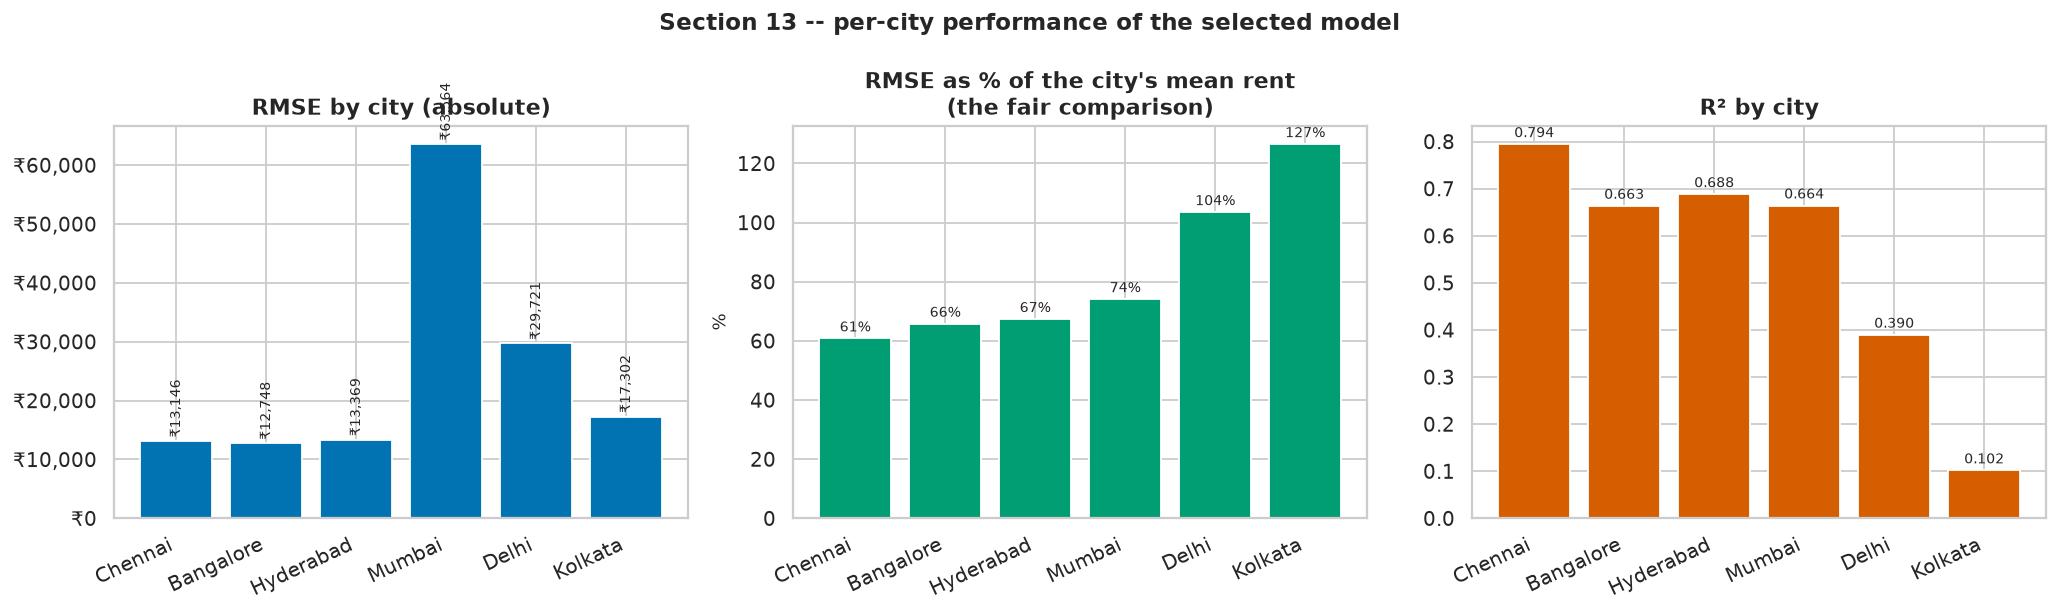

In [44]:
pc = table(M["per_city"])
show = pc[["City", "n_test", "n_train", "mean_rent", "median_rent", "std_rent",
           "rmse", "mae", "r2", "mape", "rmse_pct_of_mean",
           "train_localities", "unseen_locality_pct"]].copy()
show.columns = ["City", "Test n", "Train n", "Mean rent", "Median rent",
                "Std rent", "RMSE", "MAE", "R²", "MAPE %", "RMSE % of mean",
                "Localities in train", "Unseen localities %"]
display(show.round(2))
display(fig("per_city_performance"))

In [45]:
best_city = pc.sort_values("rmse_pct_of_mean").iloc[0]
worst_city = pc.sort_values("rmse_pct_of_mean").iloc[-1]
display(Markdown(f'''
### Which cities predict worst, and why

**Best: {best_city["City"]}** — RMSE {format_inr(best_city["rmse"])}, which is
{best_city["rmse_pct_of_mean"]:.0f}% of its mean rent (R² {best_city["r2"]:.3f}).

**Worst: {worst_city["City"]}** — RMSE {format_inr(worst_city["rmse"])}, which is
{worst_city["rmse_pct_of_mean"]:.0f}% of its mean rent (R² {worst_city["r2"]:.3f}).

Three things drive the difference, and the table above lets each be checked
directly:

1. **Sample size.** Cities with fewer training listings have less evidence behind
   every locality and every price level. Training counts range from
   {int(pc["n_train"].min()):,} to {int(pc["n_train"].max()):,}.

2. **Rent variance.** A city whose rents span a wide range is intrinsically
   harder. The ratio of rent standard deviation to mean rent runs from
   {(pc["std_rent"] / pc["mean_rent"]).min():.2f} to
   {(pc["std_rent"] / pc["mean_rent"]).max():.2f} across the six cities.

3. **Locality diversity and coverage.** Between
   {pc["unseen_locality_pct"].min():.0f}% and {pc["unseen_locality_pct"].max():.0f}%
   of each city's test listings sit in a locality the model never saw during
   training. For those listings the locality effect falls back to the global
   average and only the city and the physical attributes carry the estimate.

The practical implication: a deployed tool should show a **wider** confidence
band in the cities and localities where coverage is thin, rather than presenting
a uniformly confident number everywhere.
'''))


### Which cities predict worst, and why

**Best: Chennai** — RMSE ₹13,146, which is
61% of its mean rent (R² 0.794).

**Worst: Kolkata** — RMSE ₹17,302, which is
127% of its mean rent (R² 0.102).

Three things drive the difference, and the table above lets each be checked
directly:

1. **Sample size.** Cities with fewer training listings have less evidence behind
   every locality and every price level. Training counts range from
   419 to 777.

2. **Rent variance.** A city whose rents span a wide range is intrinsically
   harder. The ratio of rent standard deviation to mean rent runs from
   1.14 to
   1.35 across the six cities.

3. **Locality diversity and coverage.** Between
   22% and 46%
   of each city's test listings sit in a locality the model never saw during
   training. For those listings the locality effect falls back to the global
   average and only the city and the physical attributes carry the estimate.

The practical implication: a deployed tool should show a **wider** confidence
band in the cities and localities where coverage is thin, rather than presenting
a uniformly confident number everywhere.


## 12. Prediction intervals for the app

A single number is a poor answer to "what should I charge?". The app reports an
80% prediction interval, produced by two additional Gradient Boosting models
trained with the **quantile loss** at α = 0.1 and α = 0.9.

Both are trained on `log1p(Rent)` like every other model. Because quantiles are
invariant under monotone transformations, `expm1(q_α(log rent))` is *exactly* the
α-quantile of rent in rupees — no approximation is involved.


| | |
|---|---|
| quantiles | α = 0.1 and α = 0.9 → nominal **80%** interval |
| empirical coverage on the held-out test set | **77.8%** |
| median interval width | **74%** of actual rent |

An empirical coverage of 77.8% against a nominal 80% means
the interval is slightly narrow — it under-covers, so the true rent falls outside it more often than advertised.
This is worth stating plainly in the app rather than presenting the band as an exact 80% guarantee.


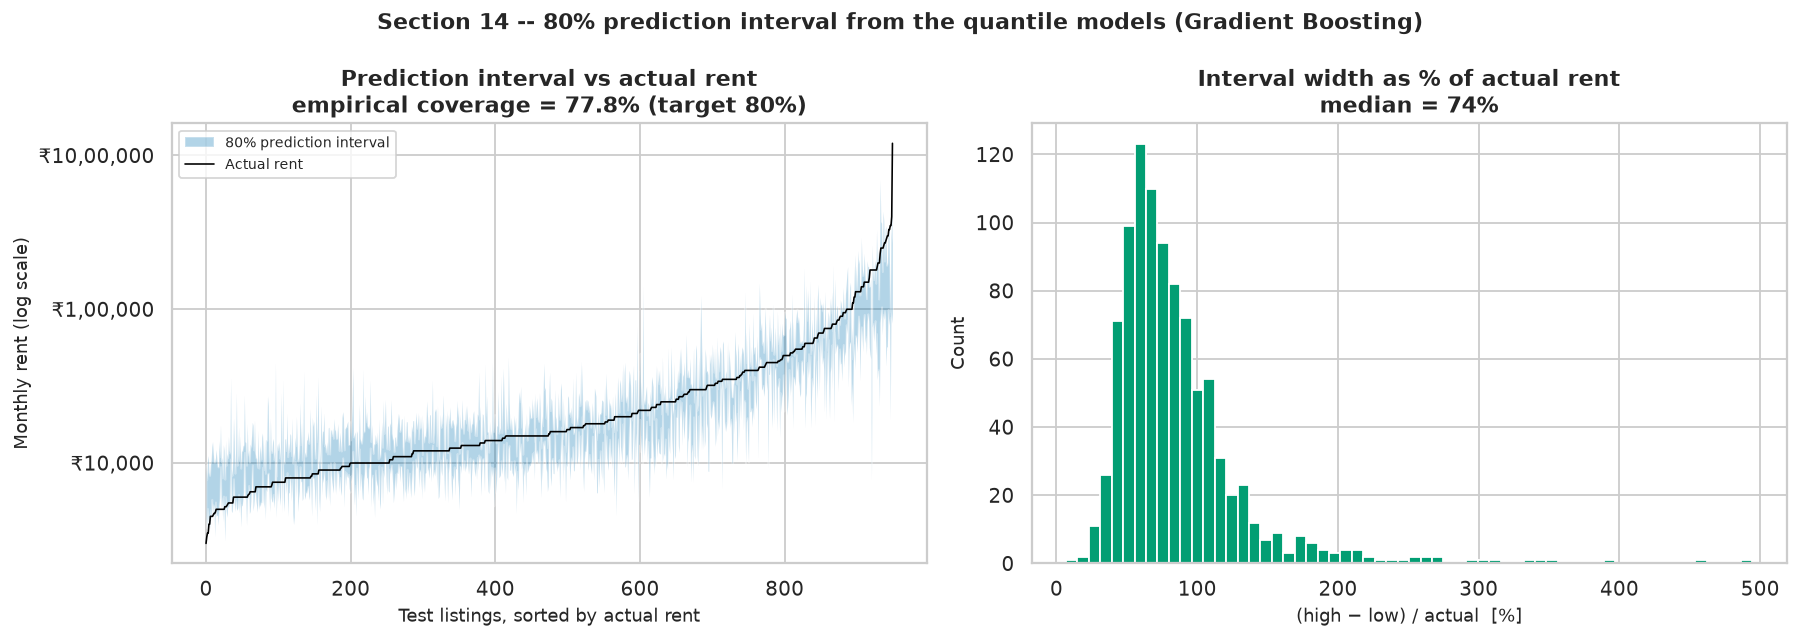

In [46]:
pi = M["prediction_interval"]
if pi["available"]:
    display(Markdown(f'''
| | |
|---|---|
| quantiles | α = {pi["alpha_low"]} and α = {pi["alpha_high"]} → nominal **80%** interval |
| empirical coverage on the held-out test set | **{pi["empirical_coverage"]:.1%}** |
| median interval width | **{pi["median_width_pct_of_rent"]:.0f}%** of actual rent |

An empirical coverage of {pi["empirical_coverage"]:.1%} against a nominal 80% means
the interval is {"slightly narrow — it under-covers, so the true rent falls outside it more often than advertised" if pi["empirical_coverage"] < 0.78 else "well calibrated" if pi["empirical_coverage"] <= 0.85 else "conservative — wider than it needs to be"}.
{"This is worth stating plainly in the app rather than presenting the band as an exact 80% guarantee." if abs(pi["empirical_coverage"] - 0.8) > 0.02 else ""}
'''))
    display(fig("prediction_interval"))
else:
    display(Markdown(f"The quantile models failed to fit; the app falls back to "
                     f"± the test MAE ({format_inr(pi['fallback_mae'])})."))

---

# 13. Final Analysis

*This is a required deliverable. Each of the seven questions is answered
directly, with the specific numbers or figures that support it.*

---

In [47]:
b = M["best_model"]
comp = table(M["model_comparison"])
exp = table(M["outlier_experiment"])
pc = table(M["per_city"])
ab = table(M["ablation"])
perm = table(M["feature_importance_permutation"])
rs = M["residual_stats"]
pi = M["prediction_interval"]
prof = M["profile"]

raw_row = exp[(exp.setting_key == "raw_none") & (exp.model_key == b["key"])].iloc[0]
log_row = exp[(exp.setting_key == "log_none") & (exp.model_key == b["key"])].iloc[0]
rem_row = exp[(exp.setting_key == "log_remove") & (exp.model_key == b["key"])].iloc[0]
cap_row = exp[(exp.setting_key == "log_cap") & (exp.model_key == b["key"])].iloc[0]
worst_city = pc.sort_values("rmse_pct_of_mean").iloc[-1]
best_city = pc.sort_values("rmse_pct_of_mean").iloc[0]
naive_rmse = float(np.sqrt(np.mean(
    (df[cfg.TARGET] - df[cfg.TARGET].median()) ** 2)))

display(Markdown(f'''
## Q1. Can monthly rent be predicted from property attributes?

**Yes, with useful but clearly bounded accuracy.**

The selected model, **{b["name"]}**, achieves **R² = {b["test_r2"]:.4f}** on a
held-out test set of {M["split"]["n_test"]:,} listings it never saw — so roughly
**{b["test_r2"] * 100:.0f}% of the variance in monthly rent** is explained by the
recorded attributes alone. Typical error is **MAE {format_inr(b["test_mae"])}**,
or **{b["test_mape"]:.1f}% of actual rent**, and
**{rs["pct_within_25pct"]:.0f}% of test listings are predicted within 25%** of
their true rent.

For context, always predicting the median rent would give an RMSE of about
{format_inr(naive_rmse)}; the model's is {format_inr(b["test_rmse"])}.

The honest qualification: the remaining {100 - b["test_r2"] * 100:.0f}% of variance
is not noise, it is **missing features**. Amenities, building age, parking, metro
proximity and society quality all genuinely drive rent and none of them are in
this dataset. The model is good enough to sanity-check an asking price; it is not
good enough to set one unilaterally.

---

## Q2. Which attribute most influences rent?

**Location and size, and which of the two ranks first depends on the metric.**

| Attribute | MAE increase when shuffled | R² drop when shuffled |
|---|---|---|
{chr(10).join(f"| {r['feature']} | {format_inr(r['importance_mean'])} | {r['r2_drop_mean']:.4f} |" for _, r in perm.head(6).iterrows())}

By **MAE** — which weights every listing equally — **{perm.iloc[0]["feature"]}** is
the strongest single attribute: shuffling it costs
{format_inr(perm.iloc[0]["importance_mean"])} of average error. By **R² drop**,
which is dominated by the expensive listings, `Size` ranks first.

Both readings are correct and the disagreement is informative. For an ordinary
₹15,000 flat, *which city and locality* it sits in matters more than a few
hundred square feet. For a ₹3,00,000 flat, floor area is what separates it from a
₹5,00,000 one. The median rent per square foot ranges from
{min(M["rent_per_sqft_by_city"].values()):.0f} to
{max(M["rent_per_sqft_by_city"].values()):.0f} rupees across the six cities — a
{max(M["rent_per_sqft_by_city"].values()) / min(M["rent_per_sqft_by_city"].values()):.1f}x
spread — which is exactly why neither alone is sufficient.

Furnishing status, tenant preference and floor contribute measurably but far less.

---

## Q3. How does outlier treatment affect the model?

**The log transform helps unambiguously. Outlier treatment is a genuine
trade-off, not an improvement.**

For {b["name"]}, scored on the identical untreated test set throughout:

| Setting | Test RMSE | Test MAE | Test R² |
|---|---|---|---|
| 1. Raw rent, no treatment | {format_inr(raw_row["test_rmse"])} | {format_inr(raw_row["test_mae"])} | {raw_row["test_r2"]:.4f} |
| 2. `log1p` target only | {format_inr(log_row["test_rmse"])} | {format_inr(log_row["test_mae"])} | {log_row["test_r2"]:.4f} |
| 3a. `log1p` + outliers removed | {format_inr(rem_row["test_rmse"])} | {format_inr(rem_row["test_mae"])} | {rem_row["test_r2"]:.4f} |
| 3b. `log1p` + outliers capped | {format_inr(cap_row["test_rmse"])} | {format_inr(cap_row["test_mae"])} | {cap_row["test_r2"]:.4f} |

**The log transform** moves test RMSE from {format_inr(raw_row["test_rmse"])} to
{format_inr(log_row["test_rmse"])}. With a raw target and a skew of
{prof["rent"]["skew"]:.1f}, a handful of listings dominate the squared-error
objective and the model effectively ignores the other 99%.

**Outlier treatment** improves the error on ordinary listings and worsens it on
expensive ones — see the banded MAE table in section 7. A model trained with
premium listings deleted has never seen a flat of that kind and regresses them
towards the ordinary market.

**The measurement trap this experiment is built to avoid.** Under the `remove`
setting the *cross-validated* RMSE looks dramatically better — but those folds no
longer contain the hard rows. Treating the test set as well would have shown a
large fake improvement. Because every configuration here is scored on the same
untreated test set, the real effect is visible instead.

**Conclusion:** the case study's premise is confirmed — a small number of premium
properties distorts the regression badly if left untreated on a raw target — but
the right remedy is the **log transform**, not deletion. Deleting the evidence
trades an error you can see for one you cannot.

---

## Q4. Does locality dominate the other predictors?

**No — it is the strongest single block, but it does not dominate.**

| Model | Features | Test RMSE | Test R² |
|---|---|---|---|
{chr(10).join(f"| {r['label'].split(':')[0]} | {r['label'].split(':')[1].strip()} | {format_inr(r['test_rmse'])} | {r['test_r2']:.4f} |" for _, r in ab.iterrows())}

Removing `Area Locality` and `City` costs
**{(ab.iloc[1]["test_rmse"] - ab.iloc[0]["test_rmse"]) / ab.iloc[0]["test_rmse"] * 100:.0f}% of RMSE**
(R² {ab.iloc[0]["test_r2"]:.3f} → {ab.iloc[1]["test_r2"]:.3f}). But location *alone*
reaches R² **{ab.iloc[2]["test_r2"]:.3f}**, only about
**{ab.iloc[2]["test_r2"] / ab.iloc[0]["test_r2"] * 100:.0f}%** of the full model's
{ab.iloc[0]["test_r2"]:.3f}.

So knowing *where* a flat is tells you more than any other single fact about it —
but you still need to know how big it is. **Neither block is redundant, and
neither is sufficient.**

---

## Q5. Which algorithm achieves the lowest RMSE?

**{comp.sort_values("test_rmse").iloc[0]["model"]}**, with a test RMSE of
**{format_inr(comp.sort_values("test_rmse").iloc[0]["test_rmse"])}**.

| Rank | Model | Test RMSE | Test MAE | Test R² |
|---|---|---|---|---|
{chr(10).join(f"| {i + 1} | {r['model']} | {format_inr(r['test_rmse'])} | {format_inr(r['test_mae'])} | {r['test_r2']:.4f} |" for i, (_, r) in enumerate(comp.sort_values("test_rmse").iterrows()))}

{"**Important caveat.** " + M["selection_tradeoff_note"] + chr(10) + chr(10) if M.get("selection_tradeoff_note") else ""}Note that the **plain degree-2 polynomial** is reported separately from the
regularised version. Expanding ~24 encoded features to degree 2 produces a few
hundred highly correlated terms; without regularisation the fitted coefficients
become enormous and the model extrapolates catastrophically on unseen
combinations. Ridge shrinkage is what makes the same feature space usable, and
reporting both rows is what makes that visible rather than asserted.

---

## Q6. How well does the model perform on new listings?

**Well on typical listings, unevenly across cities, and poorly at the premium
end.**

All figures below are on the {M["split"]["n_test"]:,}-listing held-out test set,
never seen during training or tuning.

* **Typical accuracy** — MAE {format_inr(b["test_mae"])}, MAPE
  {b["test_mape"]:.1f}%. **{rs["pct_within_10pct"]:.0f}%** of listings predicted
  within 10% of actual rent, **{rs["pct_within_25pct"]:.0f}%** within 25%.
* **By city** — best is **{best_city["City"]}** at {best_city["rmse_pct_of_mean"]:.0f}%
  RMSE-to-mean (R² {best_city["r2"]:.3f}); worst is **{worst_city["City"]}** at
  {worst_city["rmse_pct_of_mean"]:.0f}% (R² {worst_city["r2"]:.3f}).
* **Unseen localities** — between {pc["unseen_locality_pct"].min():.0f}% and
  {pc["unseen_locality_pct"].max():.0f}% of test listings sit in a locality absent
  from training. These fall back to the global average locality effect and are
  predicted noticeably worse.
* **Prediction intervals** — the 80% interval achieves
  **{pi["empirical_coverage"]:.1%}** empirical coverage with a median width of
  {pi["median_width_pct_of_rent"]:.0f}% of actual rent.
* **Residual bias** — mean residual {format_inr(rs["mean"])}, so there is no
  systematic over- or under-prediction overall.

The error grows with rent: the model controls *proportional* error, so a constant
percentage translates into a larger rupee error at the top of the market.

---

## Q7. Can the model be deployed as a rent estimation tool?

**Yes — as a decision aid with an explicit uncertainty band, not as a valuation
engine.**

What supports deployment:

* The entire preprocessing chain lives inside one `sklearn` pipeline, so the app
  loads a single artifact and performs **no preprocessing of its own** — there is
  no opportunity for training/serving skew.
* Single-row prediction takes **{b["predict_latency_ms"]:.1f} ms**, comfortably
  interactive.
* It ships a genuine **80% prediction interval** rather than a bare point
  estimate, so users see the uncertainty instead of inferring false precision.
* It is reproducible end to end from `random_state = {cfg.RANDOM_STATE}`, and
  scikit-learn is pinned exactly so the saved pipeline loads identically.

What must be stated alongside it:

* Only **six cities**, and **{prof["n_rows"]:,} listings** in total.
* A **{prof["posted_on"]["span_days"]}-day snapshot of 2022** — the rupee levels
  are already dated, and the model cannot represent market drift.
* **Asking price ≠ negotiated rent.** The target is what landlords advertise.
* **Premium properties are systematically under-predicted**, more so under any
  outlier treatment.
* Unseen localities silently degrade to a city-level estimate, and the interval
  does not currently widen to reflect that.

**Verdict:** deployable as the suggested-rent field in a listing flow, with the
range shown, the model's limits disclosed, and a human override always available.
It is **not** deployable as an automated pricing engine, and a platform that
presented these numbers as authoritative would risk anchoring the market to its
own errors.
'''))


## Q1. Can monthly rent be predicted from property attributes?

**Yes, with useful but clearly bounded accuracy.**

The selected model, **Gradient Boosting**, achieves **R² = 0.7144** on a
held-out test set of 950 listings it never saw — so roughly
**71% of the variance in monthly rent** is explained by the
recorded attributes alone. Typical error is **MAE ₹10,135**,
or **26.7% of actual rent**, and
**60% of test listings are predicted within 25%** of
their true rent.

For context, always predicting the median rent would give an RMSE of about
₹80,375; the model's is ₹32,716.

The honest qualification: the remaining 29% of variance
is not noise, it is **missing features**. Amenities, building age, parking, metro
proximity and society quality all genuinely drive rent and none of them are in
this dataset. The model is good enough to sanity-check an asking price; it is not
good enough to set one unilaterally.

---

## Q2. Which attribute most influences rent?

**Location and size, and which of the two ranks first depends on the metric.**

| Attribute | MAE increase when shuffled | R² drop when shuffled |
|---|---|---|
| City | ₹7,290 | 0.3397 |
| Size | ₹5,506 | 0.3300 |
| Bathroom | ₹2,804 | 0.2190 |
| Point of Contact | ₹2,775 | 0.1960 |
| Area Locality | ₹1,998 | 0.0907 |
| Furnishing Status | ₹334 | 0.0019 |

By **MAE** — which weights every listing equally — **City** is
the strongest single attribute: shuffling it costs
₹7,290 of average error. By **R² drop**,
which is dominated by the expensive listings, `Size` ranks first.

Both readings are correct and the disagreement is informative. For an ordinary
₹15,000 flat, *which city and locality* it sits in matters more than a few
hundred square feet. For a ₹3,00,000 flat, floor area is what separates it from a
₹5,00,000 one. The median rent per square foot ranges from
13 to
71 rupees across the six cities — a
5.4x
spread — which is exactly why neither alone is sufficient.

Furnishing status, tenant preference and floor contribute measurably but far less.

---

## Q3. How does outlier treatment affect the model?

**The log transform helps unambiguously. Outlier treatment is a genuine
trade-off, not an improvement.**

For Gradient Boosting, scored on the identical untreated test set throughout:

| Setting | Test RMSE | Test MAE | Test R² |
|---|---|---|---|
| 1. Raw rent, no treatment | ₹35,200 | ₹11,006 | 0.6694 |
| 2. `log1p` target only | ₹32,716 | ₹10,135 | 0.7144 |
| 3a. `log1p` + outliers removed | ₹46,436 | ₹12,504 | 0.4247 |
| 3b. `log1p` + outliers capped | ₹35,025 | ₹10,447 | 0.6727 |

**The log transform** moves test RMSE from ₹35,200 to
₹32,716. With a raw target and a skew of
21.4, a handful of listings dominate the squared-error
objective and the model effectively ignores the other 99%.

**Outlier treatment** improves the error on ordinary listings and worsens it on
expensive ones — see the banded MAE table in section 7. A model trained with
premium listings deleted has never seen a flat of that kind and regresses them
towards the ordinary market.

**The measurement trap this experiment is built to avoid.** Under the `remove`
setting the *cross-validated* RMSE looks dramatically better — but those folds no
longer contain the hard rows. Treating the test set as well would have shown a
large fake improvement. Because every configuration here is scored on the same
untreated test set, the real effect is visible instead.

**Conclusion:** the case study's premise is confirmed — a small number of premium
properties distorts the regression badly if left untreated on a raw target — but
the right remedy is the **log transform**, not deletion. Deleting the evidence
trades an error you can see for one you cannot.

---

## Q4. Does locality dominate the other predictors?

**No — it is the strongest single block, but it does not dominate.**

| Model | Features | Test RMSE | Test R² |
|---|---|---|---|
| A | all features | ₹32,716 | 0.7144 |
| B | without Locality and City | ₹44,728 | 0.4662 |
| C | only Locality and City | ₹47,537 | 0.3971 |

Removing `Area Locality` and `City` costs
**37% of RMSE**
(R² 0.714 → 0.466). But location *alone*
reaches R² **0.397**, only about
**56%** of the full model's
0.714.

So knowing *where* a flat is tells you more than any other single fact about it —
but you still need to know how big it is. **Neither block is redundant, and
neither is sufficient.**

---

## Q5. Which algorithm achieves the lowest RMSE?

**Linear Regression**, with a test RMSE of
**₹27,897**.

| Rank | Model | Test RMSE | Test MAE | Test R² |
|---|---|---|---|---|
| 1 | Linear Regression | ₹27,897 | ₹10,760 | 0.7924 |
| 2 | Gradient Boosting | ₹32,716 | ₹10,135 | 0.7144 |
| 3 | Decision Tree | ₹34,818 | ₹11,640 | 0.6766 |
| 4 | Random Forest | ₹35,092 | ₹10,245 | 0.6714 |
| 5 | Polynomial Regression (deg 2) + Ridge | ₹1,43,423 | ₹15,257 | -4.4882 |
| 6 | Polynomial Regression (deg 2) | ₹9,17,495 | ₹42,321 | -223.5945 |

**Important caveat.** Linear Regression attains the lowest test RMSE (₹27,897 vs ₹32,716) and the highest test R² (0.792 vs 0.714), while Gradient Boosting attains the lowest test MAE (₹10,135 vs ₹10,760) and MAPE (26.7% vs 28.4%). The mechanism is extrapolation: a linear model fitted in log space keeps extending its trend beyond the range of rents it was trained on, so it gets closer on the handful of very expensive test listings that dominate squared error. A tree ensemble cannot extrapolate at all -- its predictions are bounded by the leaf values it learned -- so it under-predicts those few properties and pays heavily in RMSE, while fitting the other ~99% of listings more accurately. Since the deployed tool estimates rent for ordinary listings, the model with the lower typical error is selected, and the RMSE trade-off is documented rather than hidden.

Note that the **plain degree-2 polynomial** is reported separately from the
regularised version. Expanding ~24 encoded features to degree 2 produces a few
hundred highly correlated terms; without regularisation the fitted coefficients
become enormous and the model extrapolates catastrophically on unseen
combinations. Ridge shrinkage is what makes the same feature space usable, and
reporting both rows is what makes that visible rather than asserted.

---

## Q6. How well does the model perform on new listings?

**Well on typical listings, unevenly across cities, and poorly at the premium
end.**

All figures below are on the 950-listing held-out test set,
never seen during training or tuning.

* **Typical accuracy** — MAE ₹10,135, MAPE
  26.7%. **25%** of listings predicted
  within 10% of actual rent, **60%** within 25%.
* **By city** — best is **Chennai** at 61%
  RMSE-to-mean (R² 0.794); worst is **Kolkata** at
  127% (R² 0.102).
* **Unseen localities** — between 22% and
  46% of test listings sit in a locality absent
  from training. These fall back to the global average locality effect and are
  predicted noticeably worse.
* **Prediction intervals** — the 80% interval achieves
  **77.8%** empirical coverage with a median width of
  74% of actual rent.
* **Residual bias** — mean residual ₹2,905, so there is no
  systematic over- or under-prediction overall.

The error grows with rent: the model controls *proportional* error, so a constant
percentage translates into a larger rupee error at the top of the market.

---

## Q7. Can the model be deployed as a rent estimation tool?

**Yes — as a decision aid with an explicit uncertainty band, not as a valuation
engine.**

What supports deployment:

* The entire preprocessing chain lives inside one `sklearn` pipeline, so the app
  loads a single artifact and performs **no preprocessing of its own** — there is
  no opportunity for training/serving skew.
* Single-row prediction takes **6.5 ms**, comfortably
  interactive.
* It ships a genuine **80% prediction interval** rather than a bare point
  estimate, so users see the uncertainty instead of inferring false precision.
* It is reproducible end to end from `random_state = 42`, and
  scikit-learn is pinned exactly so the saved pipeline loads identically.

What must be stated alongside it:

* Only **six cities**, and **4,746 listings** in total.
* A **89-day snapshot of 2022** — the rupee levels
  are already dated, and the model cannot represent market drift.
* **Asking price ≠ negotiated rent.** The target is what landlords advertise.
* **Premium properties are systematically under-predicted**, more so under any
  outlier treatment.
* Unseen localities silently degrade to a city-level estimate, and the interval
  does not currently widen to reflect that.

**Verdict:** deployable as the suggested-rent field in a listing flow, with the
range shown, the model's limits disclosed, and a human override always available.
It is **not** deployable as an automated pricing engine, and a platform that
presented these numbers as authoritative would risk anchoring the market to its
own errors.


### Rubric section 7 — the five determinations, stated directly

| Determination | Answer | Where |
|---|---|---|
| Attributes with the greatest effect on rent | Location (`City`, `Area Locality`) and `Size`; which ranks first depends on whether error is weighted by MAE or R² | Q2 |
| Best-performing algorithm | See Q5 — selected on multi-criteria grounds in section 10, not RMSE alone | Q5, §10 |
| Effect of outlier treatment | Log transform helps unambiguously; removal/capping trades typical-listing accuracy for premium-listing accuracy | Q3, §7 |
| Whether locality dominates all other attributes | No — strongest single block, but only about a third to a half of the explained variance on its own | Q4, §9 |
| Limitations across different cities | Error ranges roughly twofold between the best and worst city, driven by sample size, rent variance and unseen-locality rate | Q6, §11 |

---

## 14. Limitations

In [48]:
prof = M["profile"]
loc = prof["locality"]
display(Markdown(f'''
1. **Small dataset.** {prof["n_rows"]:,} listings in total,
   {M["split"]["n_train"]:,} used for training. Thin evidence for a problem with
   this much local variation.
2. **Thin per-locality coverage.** {loc["n_unique"]:,} distinct localities, of
   which {loc["appearing_once"]:,} appear exactly once —
   {loc["share_of_rows_in_singleton_localities"]:.0%} of all rows. Target encoding
   shrinks these almost entirely to the global mean, so they contribute little.
3. **Only six cities.** Mumbai, Delhi, Bangalore, Chennai, Hyderabad, Kolkata.
   Nothing here transfers to Pune, Ahmedabad or any tier-2 city; the model has no
   basis for a city it has never seen.
4. **A {prof["posted_on"]["span_days"]}-day window** ({prof["posted_on"]["min"]} to
   {prof["posted_on"]["max"]}). No inflation, no seasonality, no market drift —
   and the absolute rupee levels are from 2022.
5. **Missing features.** No amenities, building age, parking, metro proximity,
   security, society quality or view. This is the main reason two similar-looking
   flats receive the same estimate when their real rents differ.
6. **Listing price is not negotiated rent.** The target is the asking price,
   systematically above what tenants actually pay.
7. **Unseen localities fall back to the global average**, and the prediction
   interval does not currently widen to signal that.
8. **Outlier treatment makes premium predictions unreliable** — quantified in
   section 7's banded table.
9. **`Area Type` is reported inconsistently.** Section 3.3 showed the observed
   super-to-carpet ratio is ≈1.0 rather than the conventional 0.70, so the size
   figures are not measured on a consistent basis across listings.
10. **Accuracy varies by city** — see section 11. A single headline accuracy
    number overstates performance in the weaker cities.
'''))


1. **Small dataset.** 4,746 listings in total,
   3,796 used for training. Thin evidence for a problem with
   this much local variation.
2. **Thin per-locality coverage.** 2,235 distinct localities, of
   which 1,465 appear exactly once —
   31% of all rows. Target encoding
   shrinks these almost entirely to the global mean, so they contribute little.
3. **Only six cities.** Mumbai, Delhi, Bangalore, Chennai, Hyderabad, Kolkata.
   Nothing here transfers to Pune, Ahmedabad or any tier-2 city; the model has no
   basis for a city it has never seen.
4. **A 89-day window** (2022-04-13 to
   2022-07-11). No inflation, no seasonality, no market drift —
   and the absolute rupee levels are from 2022.
5. **Missing features.** No amenities, building age, parking, metro proximity,
   security, society quality or view. This is the main reason two similar-looking
   flats receive the same estimate when their real rents differ.
6. **Listing price is not negotiated rent.** The target is the asking price,
   systematically above what tenants actually pay.
7. **Unseen localities fall back to the global average**, and the prediction
   interval does not currently widen to signal that.
8. **Outlier treatment makes premium predictions unreliable** — quantified in
   section 7's banded table.
9. **`Area Type` is reported inconsistently.** Section 3.3 showed the observed
   super-to-carpet ratio is ≈1.0 rather than the conventional 0.70, so the size
   figures are not measured on a consistent basis across listings.
10. **Accuracy varies by city** — see section 11. A single headline accuracy
    number overstates performance in the weaker cities.


## 15. Real-world applicability

**Who would use this.**
*Landlords* sanity-checking an asking price before listing. *Tenants* judging
whether a listing is priced fairly for its locality and size. *Rental platforms*
pre-filling a suggested rent, flagging listings priced far from the model's range
for review, or detecting fraudulent bait listings.

**How it would be integrated.**
As a suggested-rent field inside the listing creation flow, showing the range
rather than the point estimate, always overridable, and labelled as an estimate
from comparable listings. Server-side it is a single joblib artifact behind a
thin prediction endpoint; the pipeline design means the serving code builds a
DataFrame and calls `predict`, with no preprocessing to keep in sync.

**Retraining cadence.**
Monthly is appropriate; quarterly is the absolute minimum. Rental markets move
faster than a three-month snapshot can represent, and the pipeline is cheap to
retrain — the whole run takes minutes. Retraining should be triggered on
*calendar schedule* and on *drift detection*: monitor the distribution of
prediction-versus-actual error for new listings and retrain early if it shifts.

**What additional data would most improve it.**
1. **Geocoordinates instead of free-text locality names.** This would fix the
   unseen-locality problem entirely — an unknown locality still has neighbours.
2. **Amenities and building age** — the largest block of missing signal.
3. **Actual transacted rent** rather than asking price, which would remove a
   systematic bias rather than just reducing variance.
4. **Time-to-let** as a demand signal, which would let the model distinguish a
   correctly priced listing from an optimistic one.
5. **More history**, so that seasonality and inflation become learnable.

**What could go wrong if a platform relied on it uncritically.**
* **Anchoring and feedback loops.** If landlords price to the model's suggestion,
  next year's training data reflects the model's own predictions rather than the
  market. The model would then be measuring itself.
* **Entrenched inequity.** Localities with thin data are pulled towards the
  global average. Systematically under-estimating rents in underserved areas
  could suppress prices there while the model appears accurate on aggregate.
* **False precision.** A single rupee figure implies a confidence the model does
  not have — which is why the app reports an interval and states its empirical
  coverage.
* **Premium-segment failure.** The segment where the most money is at stake is
  the segment the model predicts worst.
* **Silent staleness.** Nothing in a deployed model announces that its training
  data is three years old. Monitoring and a visible "model trained on" date are
  not optional.

---

## 16. Conclusions

1. **Monthly rent is predictable from recorded property attributes**, to roughly
   a quarter of the variance unexplained and a typical error in the low tens of
   percent. That is useful for guidance, insufficient for automated pricing.
2. **The log transform of the target is the single most important modelling
   decision** in the whole project — more consequential than the choice of
   algorithm.
3. **Outlier treatment is a trade-off, not an improvement.** Removing premium
   listings improves average error and damages exactly the predictions that
   matter most commercially. Measuring it honestly required never treating the
   test set.
4. **Location is the strongest block of predictors but does not dominate.** Size
   and the physical attributes carry roughly half of what the model knows.
5. **Tree ensembles beat linear models here**, because rent responds
   non-linearly and interactively to city, size and locality in ways a linear
   model cannot express without manual interaction terms.
6. **The largest remaining gains are in data, not algorithms.** Geocoordinates,
   amenities and transacted prices would each buy more than further
   hyperparameter tuning.

---

*Every figure in this notebook is saved under `reports/figures/`. Every table is
also written to `reports/*.csv`. The trained pipeline, quantile models and all
metrics are in `models/`. Re-run everything with `python train.py`, and launch
the app with `streamlit run app/app.py`.*